<a href="https://colab.research.google.com/github/samanthajmichael/heloc_credit_modeling/blob/main/02_modeling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# HELOC Classification Model

This project aims to enhance the efficiency and accuracy of the HELOC application process. Specifically, it will:
- Improve Application Response Time: By automating the classification process, faster decisions on applications can be made.
- Maximize 'Goods' and Minimize 'Bads': The model will aim to correctly identify credit-worthy applicants ('goods') and reject non-credit-worthy ones ('bads'), thereby improving overall revenue generation.

## Impacts:
- Optimized Business Processes: Automation of the classification process saves time and money, reduces employee workload, and allows staff to focus on more complex tasks.
- Reduced Human Bias: Historically, loan decisions were made at the discretion of Loan Officers, whose decisions were influenced by their experience and potential implicit biases. The model uses concrete data to make decisions, reducing the risk of misclassification due to human error or bias.
- Improved Decision Explanation: The model provides explainable results, enabling communication of reasons for denial to applicants. This transparency helps applicants understand and improve on the factors influencing their application outcomes, such as income, debt levels, credit scores, or credit history length.



# Preprocessing



In [1]:
%%capture
!pip install skorecard@git+https://github.com/wesslen/skorecard
!pip install "scikit-learn==1.5.2" "category_encoders==2.6.4"
!pip install datasets

This uses the [HELOC dataset](https://huggingface.co/datasets/mstz/heloc) from the Huggingface API

In [2]:
import os
import pandas as pd
from sklearn.datasets import fetch_openml
import numpy as np
if not hasattr(np, "product"):
    np.product = np.prod

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

csv_path = '/content/heloc.csv'

# Safely remove any existing empty or corrupt file
if os.path.exists(csv_path):
    os.remove(csv_path)

# Fetch the FICO HELOC dataset from OpenML using ID 46932
heloc_data = fetch_openml(data_id=46932, as_frame=True, parser='auto')
df = heloc_data.frame

# Save the dataset to /content/heloc.csv as requested
df.to_csv(csv_path, index=False)

# Map the target variable
if 'RiskPerformance' in df.columns:
    # Map 'Bad' to 1 (at risk) and 'Good' to 0
    df['is_at_risk'] = df['RiskPerformance'].map({'Bad': 1, 'Good': 0})
    df = df.drop(columns=['RiskPerformance'])

# Map original column names to match the names used in downstream analysis
rename_dict = {
    'MSinceMostRecentDelq': 'months_since_last_illegal_trade',
    'MaxDelqEver': 'maximum_illegal_trades',
    'NumTotalTrades': 'nr_total_trades',
    'NumInqLast6M': 'nr_inquiries_in_last_6_months',
    'NetFractionRevolvingBurden': 'net_fraction_of_revolving_burden',
    'NumBank2NatlTradesWHighUtilization': 'nr_banks_with_high_ratio',
    'ExternalRiskEstimate': 'estimate_of_risk',
    'MSinceOldestTradeOpen': 'months_since_first_trade',
    'MSinceMostRecentTradeOpen': 'months_since_last_trade',
    'NumSatisfactoryTrades': 'number_of_satisfactory_trades',
    'PercentTradesNeverDelq': 'percentage_of_legal_trades',
    'NumTrades90DerogAfter12M': 'nr_trades_insolvent_for_over_90_days'
}
df = df.rename(columns=rename_dict)

df_original = df.copy()
df = df_original.copy()
df.head()

,estimate_of_risk,months_since_first_trade,months_since_last_trade,AverageMInFile,number_of_satisfactory_trades,NumTrades60Ever2DerogPubRec,NumTrades90Ever2DerogPubRec,percentage_of_legal_trades,months_since_last_illegal_trade,MaxDelq2PublicRecLast12M,maximum_illegal_trades,nr_total_trades,NumTradesOpeninLast12M,PercentInstallTrades,MSinceMostRecentInqexcl7days,nr_inquiries_in_last_6_months,NumInqLast6Mexcl7days,net_fraction_of_revolving_burden,NetFractionInstallBurden,NumRevolvingTradesWBalance,NumInstallTradesWBalance,nr_banks_with_high_ratio,PercentTradesWBalance,is_at_risk
0,61,350,5,92,33,2,0,86,1,3,5,36,5,25,0,1,1,43,74,6,3,1,53,1
1,81,213,4,75,40,0,0,100,-7,7,8,40,2,35,3,2,2,30,97,4,4,0,62,0
2,56,167,19,86,14,1,0,80,4,4,5,15,0,20,0,0,0,93,25,5,2,1,100,1
3,85,124,2,44,3,0,0,100,-7,7,8,4,2,25,4,1,1,0,100,0,1,-8,50,1
4,76,190,1,72,11,0,0,92,24,6,6,25,2,17,1,3,3,36,-8,5,1,2,67,0


In [3]:
df.dtypes

,0
estimate_of_risk,int64
months_since_first_trade,int64
months_since_last_trade,int64
AverageMInFile,int64
number_of_satisfactory_trades,int64
NumTrades60Ever2DerogPubRec,int64
NumTrades90Ever2DerogPubRec,int64
percentage_of_legal_trades,int64
months_since_last_illegal_trade,int64
MaxDelq2PublicRecLast12M,int64


In [4]:
# Fix the missing column by mapping 'NumTrades90Ever2DerogPubRec' (from OpenML) to 'nr_trades_insolvent_for_over_90_days' if needed
if 'NumTrades90Ever2DerogPubRec' in df.columns and 'nr_trades_insolvent_for_over_90_days' not in df.columns:
    df = df.rename(columns={'NumTrades90Ever2DerogPubRec': 'nr_trades_insolvent_for_over_90_days'})

X = df[['estimate_of_risk', 'months_since_first_trade', 'months_since_last_trade', 'number_of_satisfactory_trades', 'nr_trades_insolvent_for_over_90_days',
        'percentage_of_legal_trades', 'months_since_last_illegal_trade', 'maximum_illegal_trades', 'nr_total_trades', 'nr_inquiries_in_last_6_months',
        'net_fraction_of_revolving_burden', 'nr_banks_with_high_ratio']]
y = df['is_at_risk']

## Partitioning

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## Bucketing: The scorecard model with bucketing is the chosen methodology for this loan repayment prediction project for several reasons:

- Interpretability: Scorecards are highly interpretable, allowing clear explanations of risk factors to customers and regulators - a crucial requirement in the financial industry.

- Industry standard: Scorecards are widely used and accepted in credit risk assessment, aligning the project with established practices.

- Handling non-linear relationships: Bucketing (or binning) allows the model to capture non-linear relationships between variables and the target, potentially improving predictive power.

- Dealing with outliers: Bucketing helps mitigate the impact of outliers, making the model more robust to extreme values in the data.

- Simplicity and maintainability: Once developed, scorecards are relatively simple to implement and maintain, facilitating long-term use and updates.

(CVXPY) Oct 23 11:37:10 AM: Encountered unexpected exception importing solver HIGHS:
ImportError('/usr/local/lib/python3.13/dist-packages/highspy/_core.cpython-313-x86_64-linux-gnu.so: undefined symbol: _ZN5Highs13releaseMemoryEv')
(CVXPY) Oct 23 11:37:10 AM: Encountered unexpected exception importing solver GLOP:
RuntimeError('Unrecognized new version of ortools (9.15.6755). Expected < 9.12.0. Please open a feature request on cvxpy to enable support for this version.')
(CVXPY) Oct 23 11:37:10 AM: Encountered unexpected exception importing solver PDLP:
RuntimeError('Unrecognized new version of ortools (9.15.6755). Expected < 9.12.0. Please open a feature request on cvxpy to enable support for this version.')
(CVXPY) Oct 23 11:37:11 AM: Encountered unexpected exception importing solver HIGHS:
ImportError('/usr/local/lib/python3.13/dist-packages/highspy/_core.cpython-313-x86_64-linux-gnu.so: undefined symbol: _ZN5Highs13releaseMemoryEv')


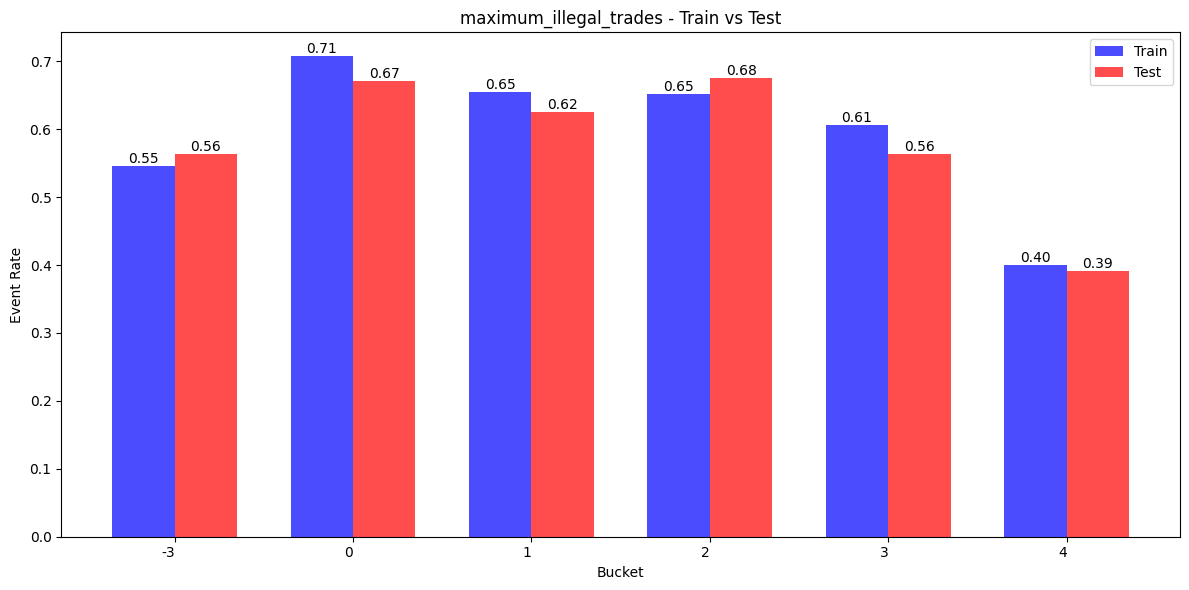

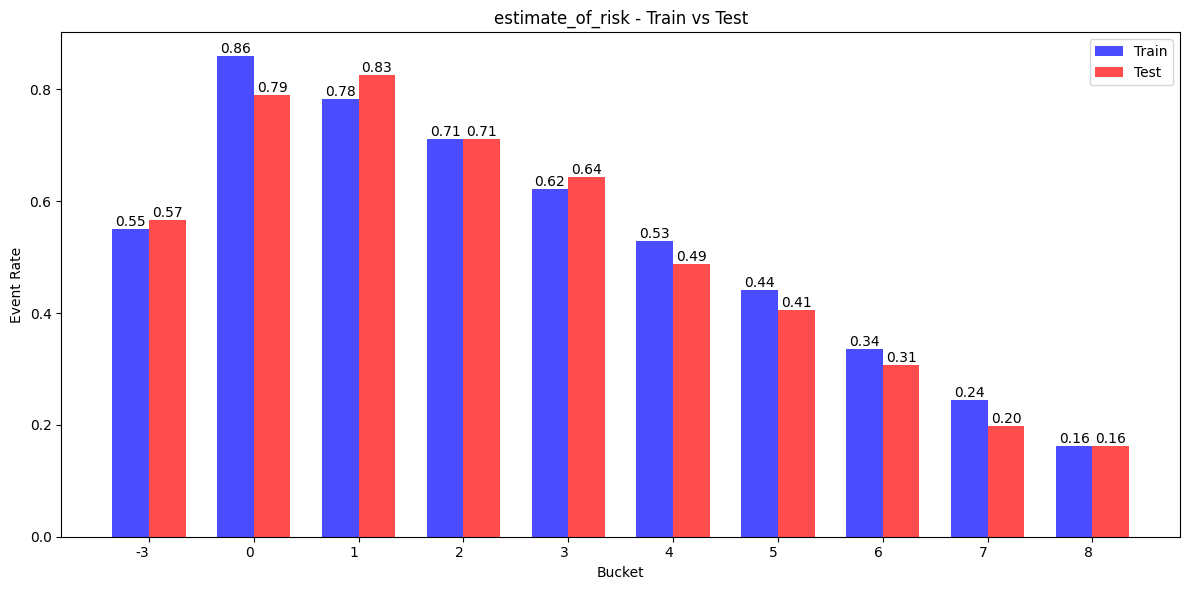

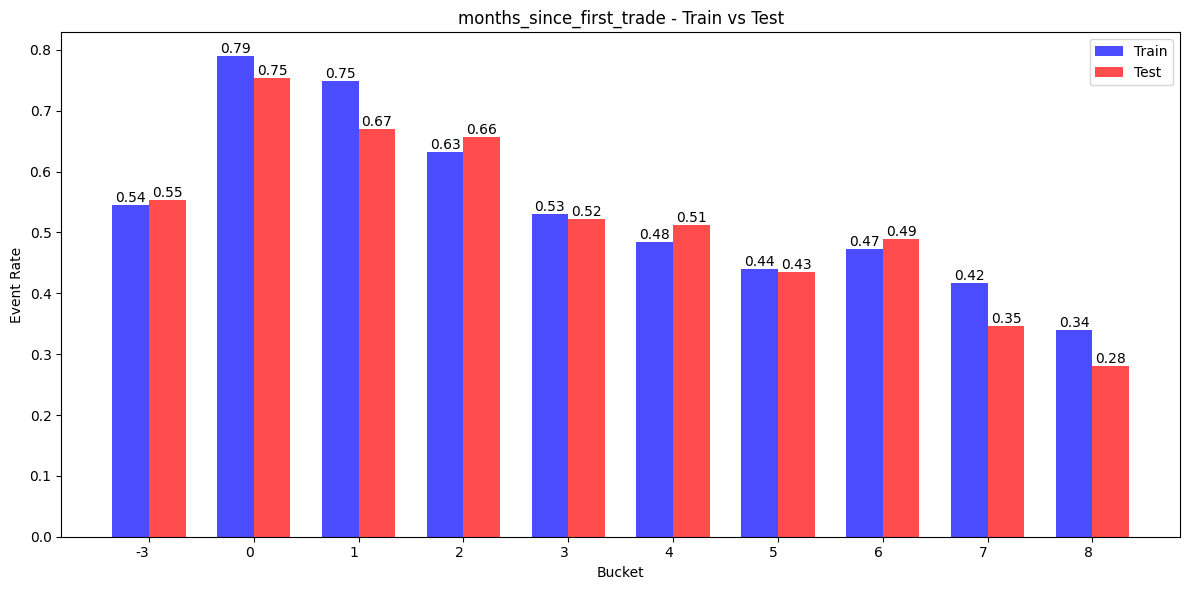

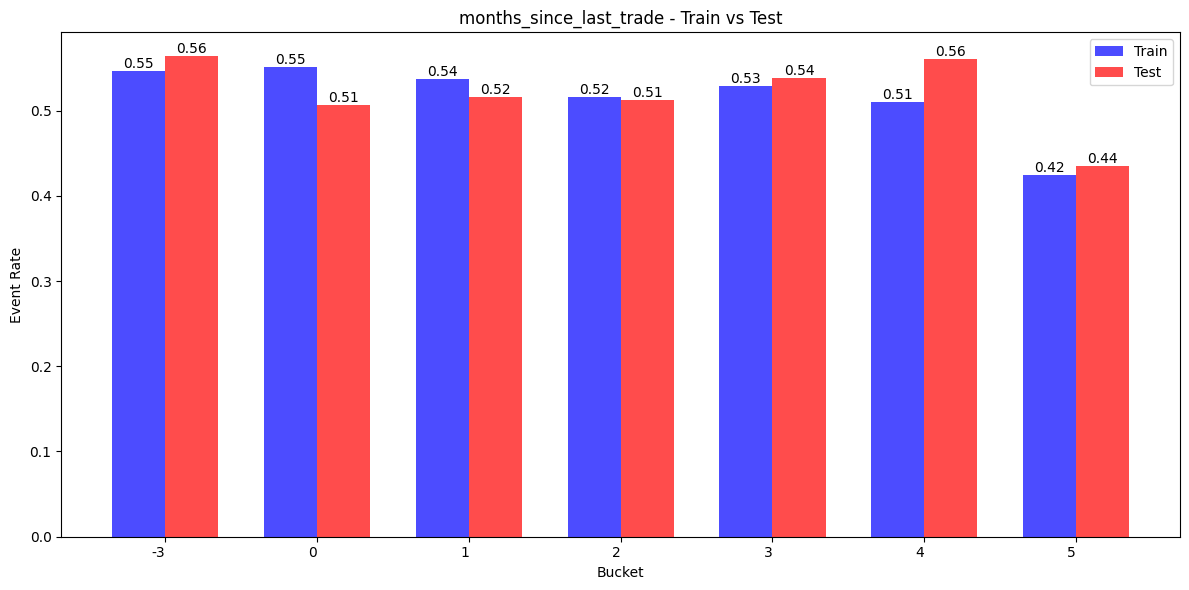

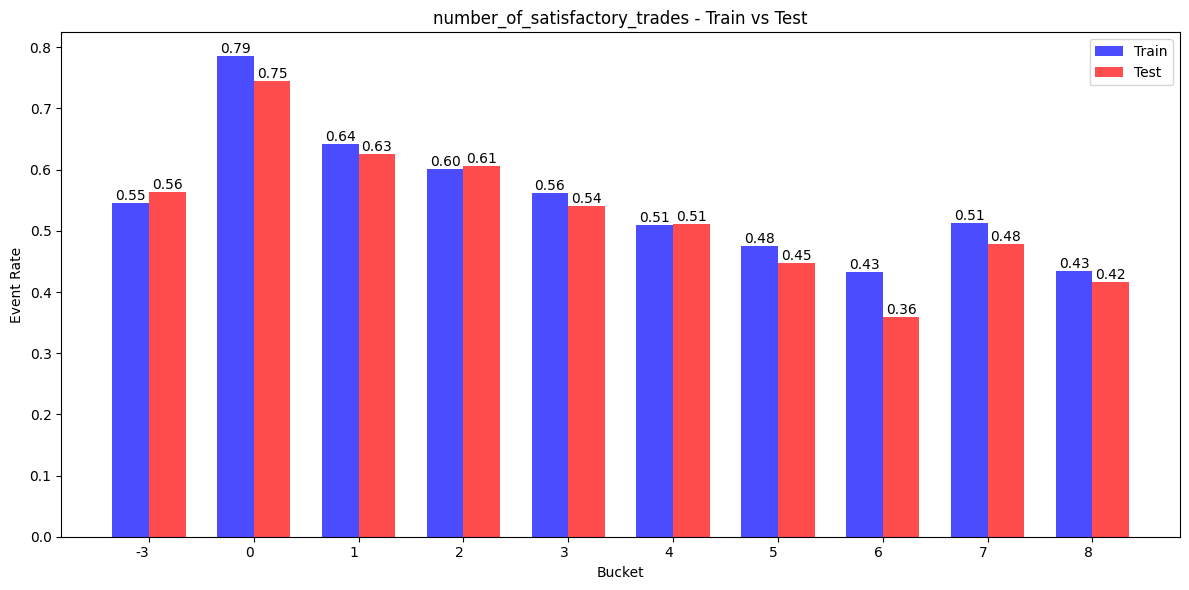

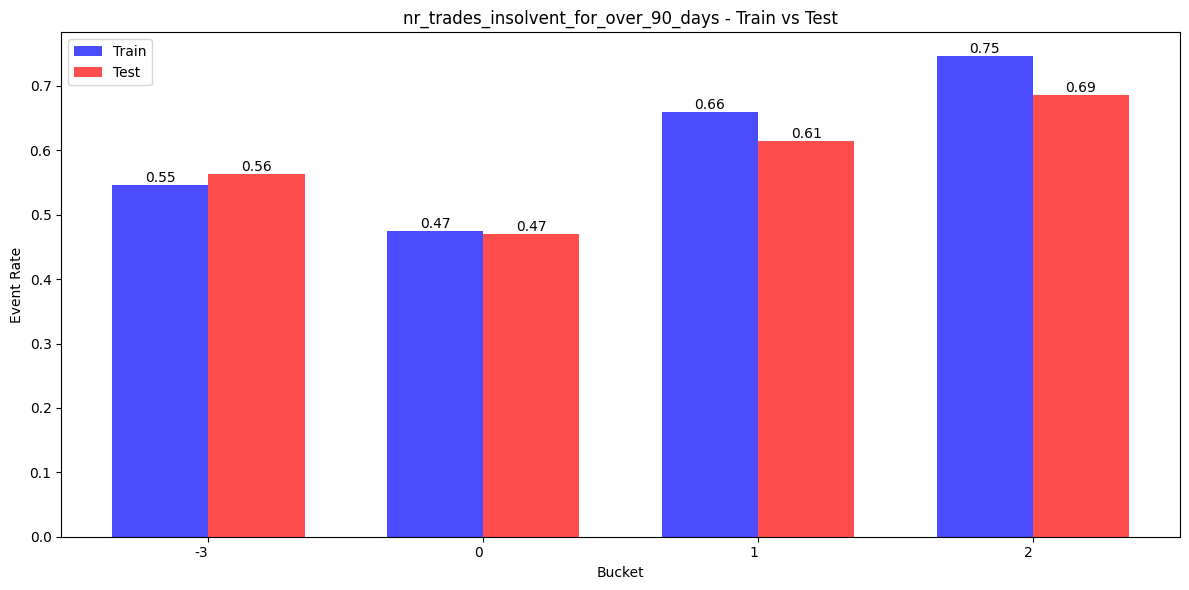

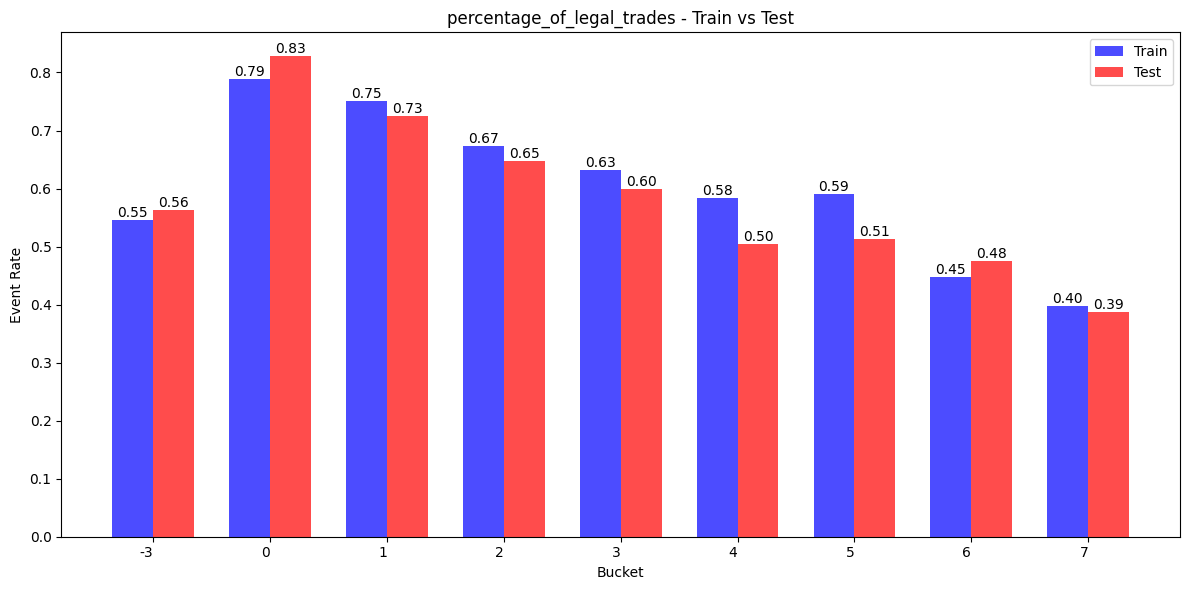

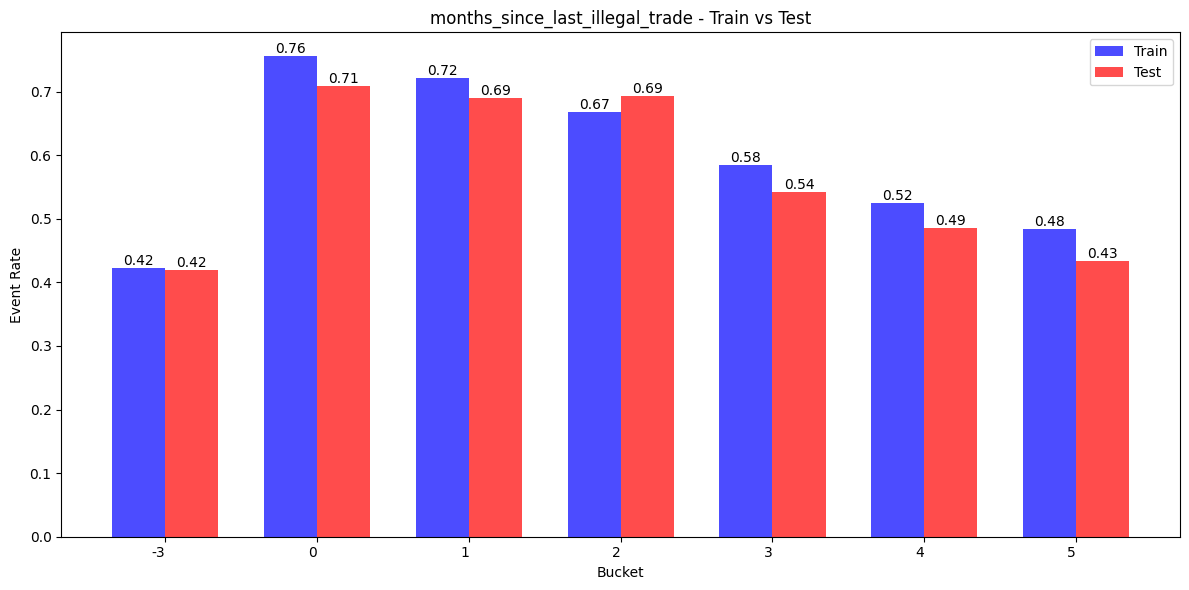

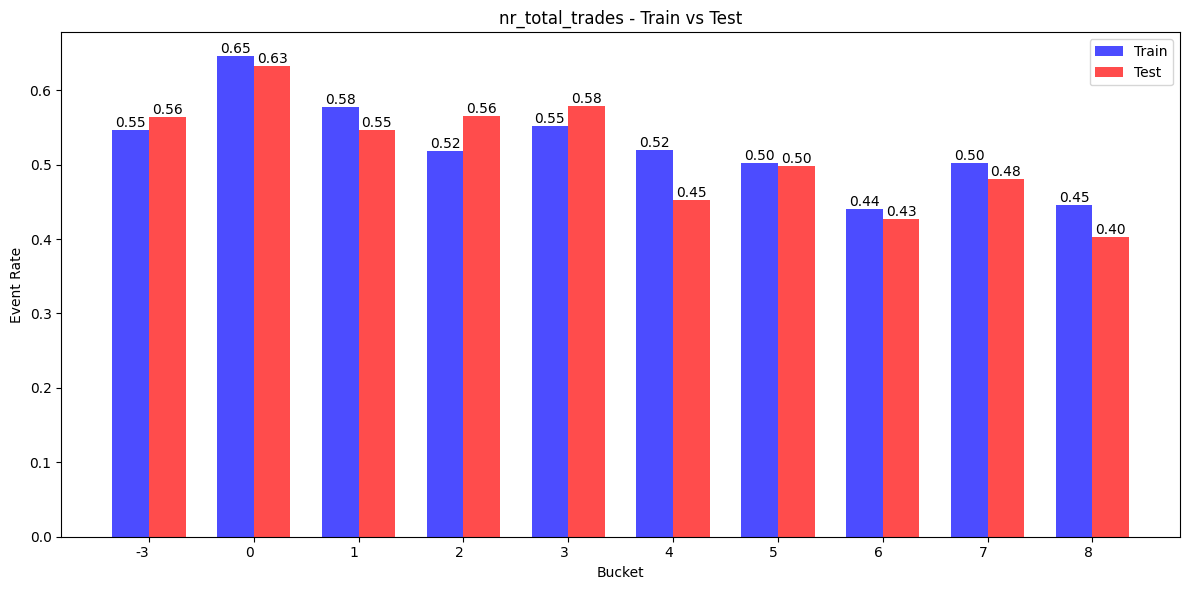

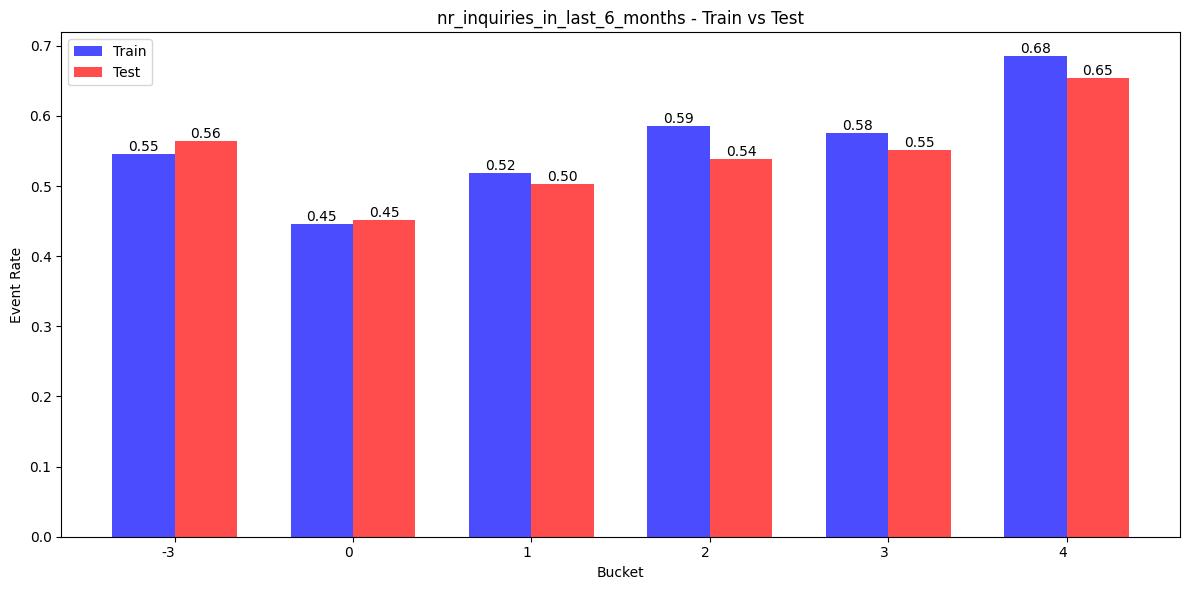

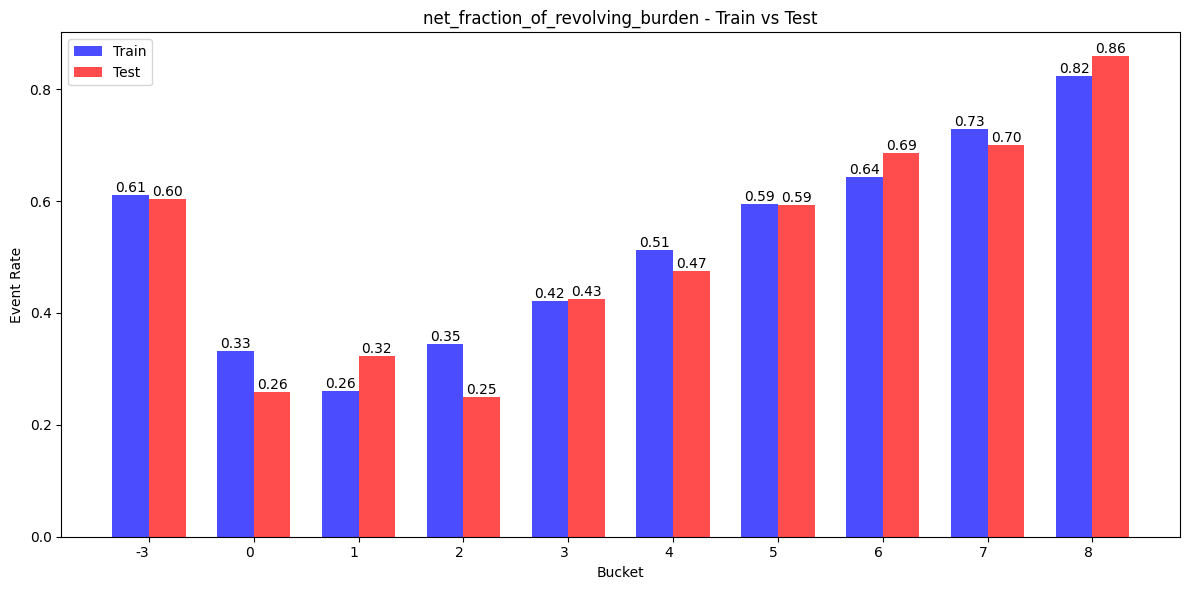

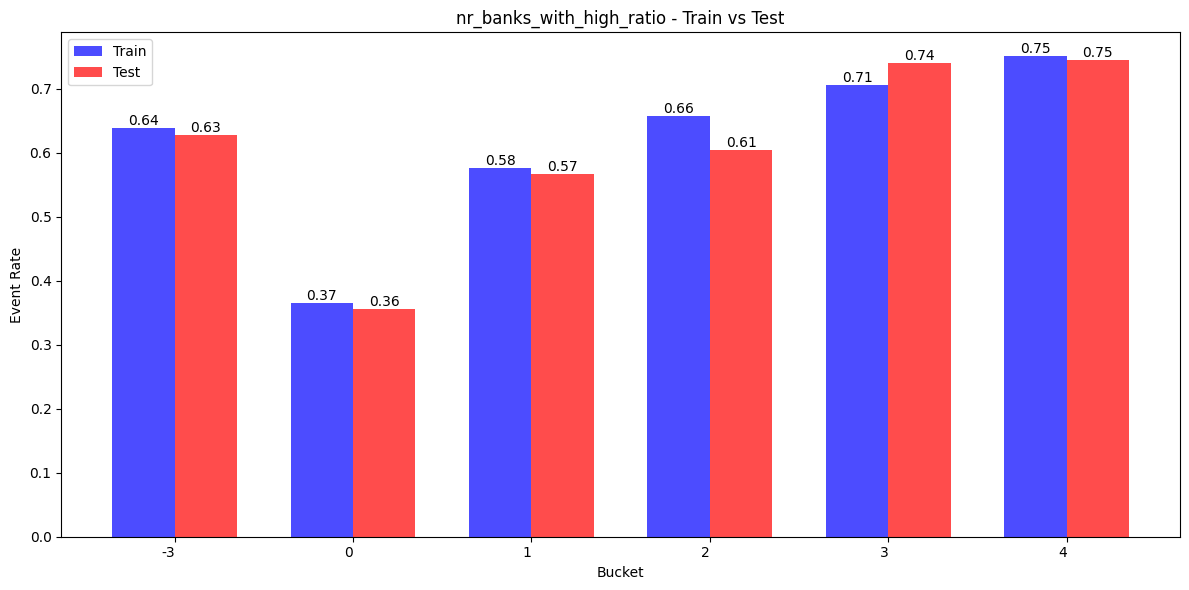

In [6]:
import warnings
warnings.filterwarnings("ignore")

from skorecard.bucketers import DecisionTreeBucketer, OptimalBucketer, EqualWidthBucketer
from skorecard.pipeline import BucketingProcess
from sklearn.pipeline import make_pipeline
import matplotlib.pyplot as plt

# Convert y_train and y_test from 'category' to integer to support mean aggregation in skorecard
y_train = y_train.astype(int)
y_test = y_test.astype(int)

# Special values definition
specials = {
    "maximum_illegal_trades": {'=NA, No Usable Data, Not Investigated': [-7, -8, -9]},
    "estimate_of_risk": {'=NA, No Usable Data, Not Investigated': [-7, -8, -9]},
    "months_since_first_trade":{'=NA, No Usable Data, Not Investigated': [-7, -8, -9]},
    "months_since_last_trade": {'=NA, No Usable Data, Not Investigated': [-7, -8, -9]},
    "number_of_satisfactory_trades": {'=NA, No Usable Data, Not Investigated': [-7, -8, -9]},
    "nr_trades_insolvent_for_over_90_days": {'=NA, No Usable Data, Not Investigated': [-7, -8, -9]},
    "percentage_of_legal_trades": {'=NA, No Usable Data, Not Investigated': [-7, -8, -9]},
    "months_since_last_illegal_trade": {'=NA, No Usable Data, Not Investigated': [-7, -8, -9]},
    "nr_total_trades": {'=NA, No Usable Data, Not Investigated': [-7, -8, -9]},
    "nr_inquiries_in_last_6_months": {'=NA, No Usable Data, Not Investigated': [-7, -8, -9]},
    "net_fraction_of_revolving_burden": {'=NA, No Usable Data, Not Investigated': [-7, -8, -9]},
    "nr_banks_with_high_ratio": {'=NA, No Usable Data, Not Investigated': [-7, -8, -9]},
}

num_cols = ['maximum_illegal_trades','estimate_of_risk', 'months_since_first_trade', 'months_since_last_trade', 'number_of_satisfactory_trades',
            'nr_trades_insolvent_for_over_90_days', 'percentage_of_legal_trades', 'months_since_last_illegal_trade', 'nr_total_trades',
            'nr_inquiries_in_last_6_months', 'net_fraction_of_revolving_burden', 'nr_banks_with_high_ratio']

# Create and fit bucketing process on training data
bucketing_process = BucketingProcess(
    prebucketing_pipeline=make_pipeline(
        EqualWidthBucketer(n_bins=100, variables=num_cols)
    ),
    bucketing_pipeline=make_pipeline(
        DecisionTreeBucketer(variables=num_cols, max_n_bins=10, min_bin_size=0.05, random_state=42)
    ),
    specials=specials
)
bucketing_process.fit(X_train, y_train)

def calculate_event_rates(X, y, variable):
    df = pd.DataFrame({'bucket': X[variable], 'target': y})
    event_rates = df.groupby('bucket')['target'].mean().reset_index()
    event_rates = event_rates.sort_values('bucket')
    return event_rates

def plot_grouped_buckets(bucketing_process, X_train, y_train, X_test, y_test, variable):
    fig, ax = plt.subplots(figsize=(12, 6))

    # Transform data
    X_train_bucketed = bucketing_process.transform(X_train)
    X_test_bucketed = bucketing_process.transform(X_test)

    # Calculate event rates
    train_event_rates = calculate_event_rates(X_train_bucketed, y_train, variable)
    test_event_rates = calculate_event_rates(X_test_bucketed, y_test, variable)

    # Plot grouped bars
    x = np.arange(len(train_event_rates['bucket']))
    width = 0.35
    ax.bar(x - width/2, train_event_rates['target'], width, label='Train', color='blue', alpha=0.7)
    ax.bar(x + width/2, test_event_rates['target'], width, label='Test', color='red', alpha=0.7)

    # Set x-axis ticks and labels
    ax.set_xticks(x)
    ax.set_xticklabels(train_event_rates['bucket'], ha='right')

    # Set labels and title
    ax.set_title(f'{variable} - Train vs Test')
    ax.set_xlabel('Bucket')
    ax.set_ylabel('Event Rate')
    ax.legend()

    # Add value labels on top of each bar
    for i, v in enumerate(train_event_rates['target']):
        ax.text(i - width/2, v, f'{v:.2f}', ha='center', va='bottom')
    for i, v in enumerate(test_event_rates['target']):
        ax.text(i + width/2, v, f'{v:.2f}', ha='center', va='bottom')

    plt.tight_layout()
    plt.show()

# Plotting grouped bars (train and test) for all variables:
for col in num_cols:
    plot_grouped_buckets(bucketing_process, X_train, y_train, X_test, y_test, col)

# **Observation:**

There are some slight differences in event rates between the train and test data but overall there is nothing egregious that would indicate poor performance.


# Exploring Buckets

The event rate of the buckets provides important information about how the target variable is distributed within each bucket created by the bucketing process.

- **Risk Segmentation:** The event rate helps identify which buckets are associated with higher or lower risk.

  - A higher event rate in a bucket indicates a higher risk group.

- **Predictive Power:** Analyzing event rates across buckets demonstrates how well the features used for bucketing differentiate between different levels of risk.

  - There should be a clear separation, with some buckets having significantly higher or lower event rates.

- **Monotonicity:** the event rate should consistently increase or decrease. Monotonic changes in event rates across buckets suggest good feature selection and bucketing.

In [7]:
bucketing_process.summary()

,column,num_prebuckets,num_buckets,IV_score,dtype
0,estimate_of_risk,102,11,0.966219,int64
1,months_since_first_trade,102,11,0.222597,int64
2,months_since_last_trade,102,8,0.021297,int64
3,number_of_satisfactory_trades,102,11,0.121104,int64
4,nr_trades_insolvent_for_over_90_days,102,5,0.137714,int64
5,percentage_of_legal_trades,102,10,0.346847,int64
6,months_since_last_illegal_trade,102,8,0.271604,int64
7,maximum_illegal_trades,102,7,0.224255,int64
8,nr_total_trades,102,11,0.056393,int64
9,nr_inquiries_in_last_6_months,102,7,0.097419,int64


## Estimate of Risk

In [8]:
bucketing_process.bucket_table("estimate_of_risk")

,bucket,label,Count,Count (%),Non-event,Event,% Event,% Non-event,Event Rate,WoE,IV
0,-3,"Special: =NA, No Usable Data, Not Investigated",485.0,5.80,218.0,267.0,6.08,5.48,0.551,0.103,0.001
1,-1,Missing,0.0,0.00,0.0,0.0,0.00,0.00,NaN,NaN,NaN
2,0,"[-inf, 43.0)",886.0,10.59,125.0,761.0,17.33,3.14,0.859,1.701,0.241
3,1,"[43.0, 49.5)",868.0,10.37,188.0,680.0,15.49,4.73,0.783,1.183,0.127
4,2,"[49.5, 56.0)",1077.0,12.87,311.0,766.0,17.45,7.82,0.711,0.801,0.077
5,3,"[56.0, 61.0)",808.0,9.66,306.0,502.0,11.44,7.69,0.621,0.395,0.015
6,4,"[61.0, 66.0)",814.0,9.73,384.0,430.0,9.79,9.66,0.528,0.014,0.000
7,5,"[66.0, 71.0)",670.0,8.01,374.0,296.0,6.74,9.40,0.442,-0.332,0.009
8,6,"[71.0, 79.0)",1095.0,13.09,728.0,367.0,8.36,18.31,0.335,-0.782,0.078
9,7,"[79.0, 84.0)",621.0,7.42,469.0,152.0,3.46,11.79,0.245,-1.221,0.102


In [9]:
bucketing_process.plot_bucket("estimate_of_risk")

## Months Since First Trade

In [10]:
bucketing_process.bucket_table("months_since_first_trade")

,bucket,label,Count,Count (%),Non-event,Event,% Event,% Non-event,Event Rate,WoE,IV
0,-3,"Special: =NA, No Usable Data, Not Investigated",668.0,7.98,304.0,364.0,8.29,7.64,0.545,0.081,0.001
1,-1,Missing,0.0,0.00,0.0,0.0,0.00,0.00,NaN,NaN,NaN
2,0,"[-inf, 10.5)",508.0,6.07,107.0,401.0,9.13,2.69,0.789,1.216,0.078
3,1,"[10.5, 14.5)",434.0,5.19,109.0,325.0,7.40,2.74,0.749,0.988,0.046
4,2,"[14.5, 21.5)",970.0,11.59,357.0,613.0,13.96,8.98,0.632,0.441,0.022
5,3,"[21.5, 28.5)",1565.0,18.70,736.0,829.0,18.88,18.51,0.530,0.020,0.000
6,4,"[28.5, 34.5)",1309.0,15.64,675.0,634.0,14.44,16.97,0.484,-0.161,0.004
7,5,"[34.5, 37.5)",428.0,5.12,240.0,188.0,4.28,6.03,0.439,-0.342,0.006
8,6,"[37.5, 42.5)",614.0,7.34,324.0,290.0,6.61,8.15,0.472,-0.209,0.003
9,7,"[42.5, 62.5)",1432.0,17.11,835.0,597.0,13.60,21.00,0.417,-0.434,0.032


In [11]:
bucketing_process.plot_bucket("months_since_first_trade")

## Months Since Last Trade

In [12]:
bucketing_process.bucket_table("months_since_last_trade")

,bucket,label,Count,Count (%),Non-event,Event,% Event,% Non-event,Event Rate,WoE,IV
0,-3,"Special: =NA, No Usable Data, Not Investigated",478.0,5.71,217.0,261.0,5.95,5.46,0.546,0.085,0.000
1,-1,Missing,0.0,0.00,0.0,0.0,0.00,0.00,NaN,NaN,NaN
2,0,"[-inf, 0.5)",2396.0,28.64,1076.0,1320.0,30.07,27.06,0.551,0.105,0.003
3,1,"[0.5, 1.5)",2294.0,27.42,1063.0,1231.0,28.04,26.73,0.537,0.048,0.001
4,2,"[1.5, 2.5)",1184.0,14.15,573.0,611.0,13.92,14.41,0.516,-0.035,0.000
5,3,"[2.5, 3.5)",719.0,8.59,339.0,380.0,8.66,8.52,0.529,0.015,0.000
6,4,"[3.5, 4.5)",423.0,5.06,207.0,216.0,4.92,5.20,0.511,-0.056,0.000
7,5,"[4.5, inf)",873.0,10.43,502.0,371.0,8.45,12.62,0.425,-0.400,0.017


In [13]:
bucketing_process.plot_bucket("months_since_last_trade")

## Number of Satisfactory Trades

In [14]:
bucketing_process.bucket_table("number_of_satisfactory_trades")

,bucket,label,Count,Count (%),Non-event,Event,% Event,% Non-event,Event Rate,WoE,IV
0,-3,"Special: =NA, No Usable Data, Not Investigated",478.0,5.71,217.0,261.0,5.95,5.46,0.546,0.085,0.000
1,-1,Missing,0.0,0.00,0.0,0.0,0.00,0.00,NaN,NaN,NaN
2,0,"[-inf, 6.5)",433.0,5.18,93.0,340.0,7.74,2.34,0.785,1.190,0.064
3,1,"[6.5, 10.5)",498.0,5.95,178.0,320.0,7.29,4.48,0.643,0.485,0.014
4,2,"[10.5, 14.0)",649.0,7.76,259.0,390.0,8.88,6.51,0.601,0.309,0.007
5,3,"[14.0, 16.5)",551.0,6.59,241.0,310.0,7.06,6.06,0.563,0.152,0.002
6,4,"[16.5, 28.0)",2604.0,31.12,1279.0,1325.0,30.18,32.16,0.509,-0.063,0.001
7,5,"[28.0, 33.0)",926.0,11.07,486.0,440.0,10.02,12.22,0.475,-0.198,0.004
8,6,"[33.0, 35.5)",446.0,5.33,253.0,193.0,4.40,6.36,0.433,-0.368,0.007
9,7,"[35.5, 39.5)",468.0,5.59,228.0,240.0,5.47,5.73,0.513,-0.048,0.000


In [15]:
bucketing_process.plot_bucket("number_of_satisfactory_trades")

## Trades Insolvent for Over 90 Days

In [16]:
bucketing_process.bucket_table('nr_trades_insolvent_for_over_90_days')

,bucket,label,Count,Count (%),Non-event,Event,% Event,% Non-event,Event Rate,WoE,IV
0,-3,"Special: =NA, No Usable Data, Not Investigated",478.0,5.71,217.0,261.0,5.95,5.46,0.546,0.085,0.000
1,-1,Missing,0.0,0.00,0.0,0.0,0.00,0.00,NaN,NaN,NaN
2,0,"[-inf, 2.5)",6093.0,72.82,3203.0,2890.0,65.83,80.54,0.474,-0.202,0.030
3,1,"[2.5, 7.5)",1166.0,13.94,397.0,769.0,17.52,9.98,0.660,0.561,0.042
4,2,"[7.5, inf)",630.0,7.53,160.0,470.0,10.71,4.02,0.746,0.975,0.065


In [17]:
bucketing_process.plot_bucket('nr_trades_insolvent_for_over_90_days')

## Percentage of Legal Trades

In [18]:
bucketing_process.bucket_table("percentage_of_legal_trades")

,bucket,label,Count,Count (%),Non-event,Event,% Event,% Non-event,Event Rate,WoE,IV
0,-3,"Special: =NA, No Usable Data, Not Investigated",478.0,5.71,217.0,261.0,5.95,5.46,0.546,0.085,0.000
1,-1,Missing,0.0,0.00,0.0,0.0,0.00,0.00,NaN,NaN,NaN
2,0,"[-inf, 74.5)",731.0,8.74,155.0,576.0,13.12,3.90,0.788,1.209,0.112
3,1,"[74.5, 82.5)",582.0,6.96,145.0,437.0,9.95,3.65,0.751,1.000,0.063
4,2,"[82.5, 87.5)",574.0,6.86,188.0,386.0,8.79,4.73,0.672,0.618,0.025
5,3,"[87.5, 90.5)",489.0,5.84,180.0,309.0,7.04,4.53,0.632,0.439,0.011
6,4,"[90.5, 92.5)",475.0,5.68,198.0,277.0,6.31,4.98,0.583,0.236,0.003
7,5,"[92.5, 94.5)",566.0,6.76,232.0,334.0,7.61,5.83,0.590,0.264,0.005
8,6,"[94.5, 96.5)",616.0,7.36,340.0,276.0,6.29,8.55,0.448,-0.307,0.007
9,7,"[96.5, inf)",3856.0,46.09,2322.0,1534.0,34.94,58.39,0.398,-0.513,0.120


In [19]:
bucketing_process.plot_bucket("percentage_of_legal_trades")

## Months Since Last Illegal Trade

In [20]:
bucketing_process.bucket_table("months_since_last_illegal_trade")

,bucket,label,Count,Count (%),Non-event,Event,% Event,% Non-event,Event Rate,WoE,IV
0,-3,"Special: =NA, No Usable Data, Not Investigated",4368.0,52.21,2525.0,1843.0,41.98,63.49,0.422,-0.413,0.089
1,-1,Missing,0.0,0.00,0.0,0.0,0.00,0.00,NaN,NaN,NaN
2,0,"[-inf, 3.5)",777.0,9.29,190.0,587.0,13.37,4.78,0.755,1.026,0.088
3,1,"[3.5, 9.5)",668.0,7.98,186.0,482.0,10.98,4.68,0.722,0.850,0.054
4,2,"[9.5, 21.5)",827.0,9.88,275.0,552.0,12.57,6.91,0.667,0.596,0.034
5,3,"[21.5, 39.5)",722.0,8.63,300.0,422.0,9.61,7.54,0.584,0.242,0.005
6,4,"[39.5, 55.5)",423.0,5.06,201.0,222.0,5.06,5.05,0.525,0.000,0.000
7,5,"[55.5, inf)",582.0,6.96,300.0,282.0,6.42,7.54,0.485,-0.160,0.002


In [21]:
bucketing_process.plot_bucket("months_since_last_illegal_trade")

## Maximum Illegal Trades

In [22]:
bucketing_process.bucket_table("maximum_illegal_trades")

,bucket,label,Count,Count (%),Non-event,Event,% Event,% Non-event,Event Rate,WoE,IV
0,-3,"Special: =NA, No Usable Data, Not Investigated",478.0,5.71,217.0,261.0,5.95,5.46,0.546,0.085,0.000
1,-1,Missing,0.0,0.00,0.0,0.0,0.00,0.00,NaN,NaN,NaN
2,0,"[-inf, 8.0)",584.0,6.98,171.0,413.0,9.41,4.30,0.707,0.780,0.040
3,1,"[8.0, 41.0)",504.0,6.02,174.0,330.0,7.52,4.38,0.655,0.539,0.017
4,2,"[41.0, 57.5)",777.0,9.29,271.0,506.0,11.53,6.81,0.651,0.524,0.025
5,3,"[57.5, 74.5)",2266.0,27.08,891.0,1375.0,31.32,22.40,0.607,0.335,0.030
6,4,"[74.5, inf)",3758.0,44.91,2253.0,1505.0,34.28,56.65,0.400,-0.502,0.112


In [23]:
bucketing_process.plot_bucket("maximum_illegal_trades")

## Total Trades

In [24]:
bucketing_process.bucket_table("nr_total_trades")

,bucket,label,Count,Count (%),Non-event,Event,% Event,% Non-event,Event Rate,WoE,IV
0,-3,"Special: =NA, No Usable Data, Not Investigated",478.0,5.71,217.0,261.0,5.95,5.46,0.546,0.085,0.000
1,-1,Missing,0.0,0.00,0.0,0.0,0.00,0.00,NaN,NaN,NaN
2,0,"[-inf, 7.5)",917.0,10.96,325.0,592.0,13.49,8.17,0.646,0.500,0.027
3,1,"[7.5, 12.5)",1058.0,12.64,447.0,611.0,13.92,11.24,0.578,0.213,0.006
4,2,"[12.5, 14.5)",538.0,6.43,259.0,279.0,6.36,6.51,0.519,-0.025,0.000
5,3,"[14.5, 16.5)",564.0,6.74,253.0,311.0,7.08,6.36,0.551,0.107,0.001
6,4,"[16.5, 19.5)",751.0,8.98,361.0,390.0,8.88,9.08,0.519,-0.022,0.000
7,5,"[19.5, 26.5)",1850.0,22.11,920.0,930.0,21.18,23.13,0.503,-0.088,0.002
8,6,"[26.5, 32.5)",926.0,11.07,518.0,408.0,9.29,13.02,0.441,-0.337,0.013
9,7,"[32.5, 39.5)",619.0,7.40,308.0,311.0,7.08,7.74,0.502,-0.089,0.001


In [25]:
bucketing_process.plot_bucket("nr_total_trades")

## Inquiries in Last 6 Months

In [26]:
bucketing_process.bucket_table("nr_inquiries_in_last_6_months")

,bucket,label,Count,Count (%),Non-event,Event,% Event,% Non-event,Event Rate,WoE,IV
0,-3,"Special: =NA, No Usable Data, Not Investigated",478.0,5.71,217.0,261.0,5.95,5.46,0.546,0.085,0.000
1,-1,Missing,0.0,0.00,0.0,0.0,0.00,0.00,NaN,NaN,NaN
2,0,"[-inf, 0.5)",3114.0,37.22,1727.0,1387.0,31.59,43.42,0.445,-0.318,0.038
3,1,"[0.5, 2.0)",2056.0,24.57,991.0,1065.0,24.26,24.92,0.518,-0.027,0.000
4,2,"[2.0, 3.5)",1200.0,14.34,497.0,703.0,16.01,12.50,0.586,0.247,0.009
5,3,"[3.5, 5.0)",605.0,7.23,257.0,348.0,7.93,6.46,0.575,0.203,0.003
6,4,"[5.0, inf)",914.0,10.92,288.0,626.0,14.26,7.24,0.685,0.676,0.047


In [27]:
bucketing_process.plot_bucket("nr_inquiries_in_last_6_months")

## Net Fraction of Revolving Burden

In [28]:
bucketing_process.bucket_table("net_fraction_of_revolving_burden")

,bucket,label,Count,Count (%),Non-event,Event,% Event,% Non-event,Event Rate,WoE,IV
0,-3,"Special: =NA, No Usable Data, Not Investigated",633.0,7.57,246.0,387.0,8.82,6.19,0.611,0.353,0.009
1,-1,Missing,0.0,0.00,0.0,0.0,0.00,0.00,NaN,NaN,NaN
2,0,"[-inf, 0.5)",968.0,11.57,647.0,321.0,7.31,16.27,0.332,-0.798,0.071
3,1,"[0.5, 2.5)",689.0,8.23,509.0,180.0,4.10,12.80,0.261,-1.135,0.099
4,2,"[2.5, 5.5)",820.0,9.80,537.0,283.0,6.45,13.50,0.345,-0.738,0.052
5,3,"[5.5, 9.5)",938.0,11.21,543.0,395.0,9.00,13.65,0.421,-0.416,0.019
6,4,"[9.5, 15.5)",1104.0,13.19,539.0,565.0,12.87,13.55,0.512,-0.052,0.000
7,5,"[15.5, 20.5)",791.0,9.45,321.0,470.0,10.71,8.07,0.594,0.282,0.007
8,6,"[20.5, 24.5)",571.0,6.82,204.0,367.0,8.36,5.13,0.643,0.486,0.016
9,7,"[24.5, 33.5)",1092.0,13.05,297.0,795.0,18.11,7.47,0.728,0.884,0.094


In [29]:
bucketing_process.plot_bucket("net_fraction_of_revolving_burden")

## Banks with High Ratio

In [30]:
bucketing_process.bucket_table("nr_banks_with_high_ratio")

,bucket,label,Count,Count (%),Non-event,Event,% Event,% Non-event,Event Rate,WoE,IV
0,-3,"Special: =NA, No Usable Data, Not Investigated",956.0,11.43,345.0,611.0,13.92,8.67,0.639,0.472,0.025
1,-1,Missing,0.0,0.00,0.0,0.0,0.00,0.00,NaN,NaN,NaN
2,0,"[-inf, 2.5)",3451.0,41.25,2188.0,1263.0,28.77,55.02,0.366,-0.648,0.170
3,1,"[2.5, 8.0)",1964.0,23.47,832.0,1132.0,25.79,20.92,0.576,0.209,0.010
4,2,"[8.0, 13.5)",989.0,11.82,339.0,650.0,14.81,8.52,0.657,0.551,0.035
5,3,"[13.5, 19.0)",497.0,5.94,146.0,351.0,8.00,3.67,0.706,0.774,0.033
6,4,"[19.0, inf)",510.0,6.10,127.0,383.0,8.72,3.19,0.751,1.000,0.055


In [31]:
bucketing_process.plot_bucket("nr_banks_with_high_ratio")

## Interpretation

- There is a distinct separation, with some buckets showing notably higher or lower event rates.

- The event rates change monotonically across buckets for each feature, suggesting good feature selection and bucketing.


#Model Training

In [32]:
from skorecard.pipeline import to_skorecard_pipeline
bucketing_process.save_yml(open("buckets.yml", "w"))

In [33]:
import yaml

buckets_dict = yaml.safe_load(open("buckets.yml"))

buckets_dict

{'estimate_of_risk': {'feature_name': 'estimate_of_risk',
  'map': [59.230000000000004,
   63.5,
   67.16,
   70.21000000000001,
   73.25999999999999,
   76.31,
   81.19,
   84.24000000000001],
  'missing_bucket': None,
  'other_bucket': None,
  'right': True,
  'specials': {'=NA, No Usable Data, Not Investigated': [-7, -8, -9]},
  'type': 'numerical'},
 'maximum_illegal_trades': {'feature_name': 'maximum_illegal_trades',
  'map': [2.48, 4.46, 5.48, 6.5],
  'missing_bucket': None,
  'other_bucket': None,
  'right': True,
  'specials': {'=NA, No Usable Data, Not Investigated': [-7, -8, -9]},
  'type': 'numerical'},
 'months_since_first_trade': {'feature_name': 'months_since_first_trade',
  'map': [68.22,
   92.3,
   134.44,
   176.57999999999998,
   212.7,
   230.76,
   260.85999999999996,
   381.26],
  'missing_bucket': None,
  'other_bucket': None,
  'right': True,
  'specials': {'=NA, No Usable Data, Not Investigated': [-7, -8, -9]},
  'type': 'numerical'},
 'months_since_last_illega

In [34]:
from skorecard import Skorecard
from skorecard.bucketers import UserInputBucketer

scorecard = Skorecard(bucketing=UserInputBucketer(buckets_dict), variables=num_cols, calculate_stats=True)
scorecard = scorecard.fit(X_train, y_train)

In [35]:
scorecard

Skorecard(bucketing=UserInputBucketer, specials={}, encoder=woe, variables=['maximum_illegal_trades', 'estimate_of_risk', 'months_since_first_trade', 'months_since_last_trade', 'number_of_satisfactory_trades', 'nr_trades_insolvent_for_over_90_days', 'percentage_of_legal_trades', 'months_since_last_illegal_trade', 'nr_total_trades', 'nr_inquiries_in_last_6_months', 'net_fraction_of_revolving_burden', 'nr_banks_with_high_ratio'], verbose=0, random_state=None, lr_kwargs={'solver': 'lbfgs'}, calculate_stats=True, classes_=[0 1], bucketing_=UserInputBucketer(features_bucket_mapping={'estimate_of_risk': {'feature_name': 'estimate_of_risk',
                                                                'map': [59.230000000000004,
                                                                        63.5,
                                                                        67.16,
                                                                        70.21000000000001,
                                                                        73.25999999999999,
                                                                        76.31,
                                                                        81.19,
                                                                        84.24000000000001],
                                                                'missing_bucket': None,
                                                                'other_bucket': None,
                                                                'right': True,
                                                                'specials': {'=NA, No Usable Data, Not Investigated': [-7,
                                                                                                                       -8,
                                                                                                                       -9]},
                                                                'type': 'numerical'},
                                           'maximum_illega...
                                                                             'other_bucket': None,
                                                                             'right': True,
                                                                             'specials': {'=NA, No Usable Data, Not Investigated': [-7,
                                                                                                                                    -8,
                                                                                                                                    -9]},
                                                                             'type': 'numerical'},
                                           'percentage_of_legal_trades': {'feature_name': 'percentage_of_legal_trades',
                                                                          'map': [75.0,
                                                                                  83.0,
                                                                                  88.0,
                                                                                  91.0,
                                                                                  93.0,
                                                                                  95.0,
                                                                                  97.0],
                                                                          'missing_bucket': None,
                                                                          'other_bucket': None,
                                                                          'right': True,
                                                                          'specials': {'=NA, No Usable Data, Not Investigated': [-7,
                                                    

In [36]:
scorecard.pipeline_

Pipeline(steps=[('bucketer',
                 UserInputBucketer(features_bucket_mapping={'estimate_of_risk': {'feature_name': 'estimate_of_risk',
                                                                                 'map': [59.230000000000004,
                                                                                         63.5,
                                                                                         67.16,
                                                                                         70.21000000000001,
                                                                                         73.25999999999999,
                                                                                         76.31,
                                                                                         81.19,
                                                                                         84.24000000000001],
                                                                                 'missing_bucket': None,
                                                                                 'other_bucket': None,
                                                                                 'right': True,
                                                                                 'specials': {'=NA, No Usable Data, Not Investigated': [-7,
                                                                                                                                        -8,
                                                                                                                                        -9]},
                                                                                 'type':...
                                           'months_since_first_trade',
                                           'months_since_last_trade',
                                           'number_of_satisfactory_trades',
                                           'nr_trades_insolvent_for_over_90_days',
                                           'percentage_of_legal_trades',
                                           'months_since_last_illegal_trade',
                                           'nr_total_trades',
                                           'nr_inquiries_in_last_6_months',
                                           'net_fraction_of_revolving_burden',
                                           'nr_banks_with_high_ratio'])),
                ('model', LogisticRegression(calculate_stats=True))])

In [37]:
#scorecard.get_params()

In [38]:
scorecard.get_stats()

,Coef.,Std.Err,z,P>|z|
const,0.086709,0.025342,3.421524,6.227119e-04
maximum_illegal_trades,-0.306223,0.108725,-2.816481,4.855285e-03
estimate_of_risk,0.486908,0.051612,9.434066,3.944914e-21
months_since_first_trade,0.537623,0.063324,8.490025,2.065920e-17
months_since_last_trade,0.540842,0.195127,2.771745,5.575661e-03
number_of_satisfactory_trades,0.709195,0.113023,6.274814,3.500516e-10
nr_trades_insolvent_for_over_90_days,0.104416,0.083996,1.243112,2.138266e-01
percentage_of_legal_trades,0.334128,0.084281,3.964453,7.356451e-05
months_since_last_illegal_trade,0.487990,0.089635,5.444196,5.203996e-08
nr_total_trades,0.220396,0.157510,1.399248,1.617387e-01


# Model Evaluation

In [39]:
from sklearn.metrics import roc_auc_score, classification_report

proba_train = scorecard.predict_proba(X_train)[:, 1]
proba_test = scorecard.predict_proba(X_test)[:, 1]

print(f"AUC train:{round(roc_auc_score(y_train, proba_train),4)}")
print(f"AUC test :{round(roc_auc_score(y_test, proba_test),4)}\n")

print(classification_report(y_test, scorecard.predict(X_test)))

AUC train:0.7886
AUC test :0.7893

              precision    recall  f1-score   support

           0       0.73      0.68      0.71      1023
           1       0.72      0.76      0.74      1069

    accuracy                           0.72      2092
   macro avg       0.73      0.72      0.72      2092
weighted avg       0.72      0.72      0.72      2092



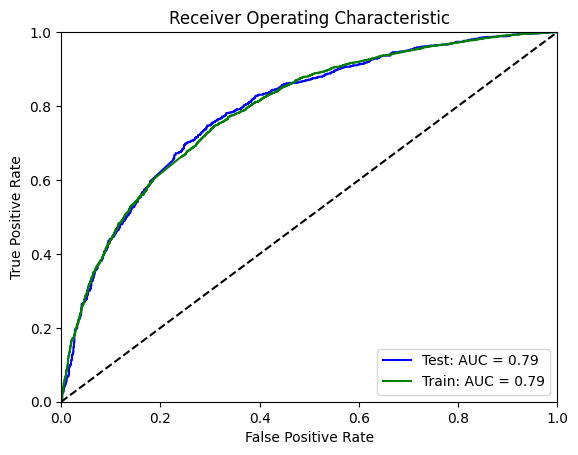

In [40]:
from matplotlib import pyplot as plt
from sklearn.metrics import roc_curve, auc

fpr1, tpr1, threshold1 = roc_curve(y_test, proba_test)
roc_auc1 = auc(fpr1, tpr1)

fpr2, tpr2, threshold2 = roc_curve(y_train, proba_train)
roc_auc2 = auc(fpr2, tpr2)

plt.title('Receiver Operating Characteristic')
plt.plot(fpr1, tpr1, 'b', label='Test: AUC = {0:.2f}'.format(roc_auc1))
plt.plot(fpr2, tpr2, 'g', label='Train: AUC = {0:.2f}'.format(roc_auc2))
plt.legend(loc='lower right')
plt.plot([0, 1], [0, 1],'k--')
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.show()

## **Observation:**
- The train AUC (0.789) and test AUC (0.789) are nearly identical, so the model performs as well on unseen data as on the data it was trained on.

- This indicates the model generalizes well and shows no sign of overfitting.

- Overall discrimination is moderate (AUC ≈ 0.79), which is a reasonable baseline for a credit-risk scorecard.

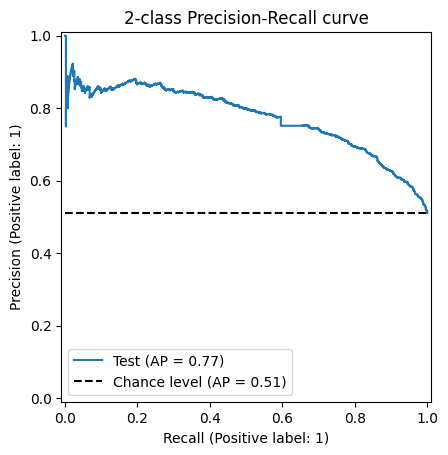

In [41]:
from sklearn.metrics import PrecisionRecallDisplay

display = PrecisionRecallDisplay.from_estimator(
    scorecard, X_test, y_test, name="Test", plot_chance_level=True
)
_ = display.ax_.set_title("2-class Precision-Recall curve")

# Feature Importance

In [42]:
from skorecard.reporting import iv

model_stats = scorecard.get_stats()

X_train_bins = scorecard.bucket_transform(X_train)
iv_dict = iv(X_train_bins, y_train)

iv_values = pd.Series(iv_dict).sort_values(ascending=False)
iv_values.name = "IV"

feat_importance = model_stats[["Coef."]].join(iv_values)
feat_importance["importance"] = -1.0 * feat_importance["Coef."] * feat_importance["IV"]
feat_importance.sort_values(by="importance", ascending=False)

,Coef.,IV,importance
maximum_illegal_trades,-0.306223,0.224255,0.068672
months_since_last_trade,0.540842,0.021297,-0.011518
nr_total_trades,0.220396,0.056393,-0.012429
nr_trades_insolvent_for_over_90_days,0.104416,0.137714,-0.014380
nr_inquiries_in_last_6_months,0.616014,0.097419,-0.060012
nr_banks_with_high_ratio,0.242565,0.328780,-0.079751
number_of_satisfactory_trades,0.709195,0.121104,-0.085886
percentage_of_legal_trades,0.334128,0.346847,-0.115891
months_since_first_trade,0.537623,0.222597,-0.119673
months_since_last_illegal_trade,0.487990,0.271604,-0.132540


The general [rule](https://www.listendata.com/2015/03/weight-of-evidence-woe-and-information.html), is IV > 0.02 should be included.

| Information Value | Variable Predictiveness     |
|:-----------------:|-----------------------------|
|   Less than 0.02  | Not useful for prediction   |
|    0.02 to 0.1    | Weak predictive Power       |
|     0.1 to 0.3    | Medium predictive Power     |
|     0.3 to 0.5    | Strong predictive Power     |
|       > 0.5       | Suspicious Predictive Power |

## **Observations:**
IV:
- All variables have IV values greater than 0.02 and will be considered for inclusion in the model. months_since_last_trade (0.021) only barely clears this threshold.
- estimate_of_risk has an IV of 0.97, which falls in the "suspicious" range (> 0.5). This is expected because it is an external risk estimate built to predict risk, but it means the model relies heavily on this one variable.

Importance: the variables in the table are sorted by their importance in descending order, but for this analysis, the absolute value of each variable's importance is considered more important.

- **High Importance:** Features with higher importance values are generally more influential in the model and contribute significantly to the model's predictive power.

  - estimate_of_risk (-0.470)
  - net_fraction_of_revolving_burden (-0.196)
  - months_since_last_illegal_trade (-0.133)
  - months_since_first_trade (-0.120)
  - percentage_of_legal_trades (-0.116)

- **Moderate Importance:** Features with moderate importance values can be considered for the model if they contribute without adding excessive complexity.

  - number_of_satisfactory_trades (-0.086)
  - nr_banks_with_high_ratio (-0.080)
  - maximum_illegal_trades (0.069), the only feature with a positive value, meaning its coefficient sign runs opposite to the others
  - nr_inquiries_in_last_6_months (-0.060)

- **Low Importance:** Features with low importance may have minimal impact on the model's performance. While they might be excluded, it's worth assessing their relevance and considering them if they provide valuable insights or improve model stability.

  - nr_trades_insolvent_for_over_90_days (-0.014)
  - nr_total_trades (-0.012)
  - months_since_last_trade (-0.012)

# Multicollinearity

In [43]:
import yaml

buckets_dict = yaml.safe_load(open("buckets.yml"))

In [44]:
from skorecard.bucketers import UserInputBucketer

uib = UserInputBucketer(buckets_dict)

In [45]:
X_train_bins = uib.fit_transform(X_train, y_train)
X_test_bins = uib.transform(X_test)

In [46]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline


def plot_correlations(corr):
    plt.figure(figsize=(10, 8), constrained_layout=True)

    cmap = plt.cm.get_cmap("RdBu")
    matrix = np.triu(corr)
    sns.heatmap(corr, vmin=-1, vmax=1, annot=True, mask=matrix, cmap=cmap, annot_kws={"fontsize": 6})

In [47]:
from skorecard.preprocessing import WoeEncoder
from sklearn.pipeline import make_pipeline

woe_pipe = make_pipeline(uib, WoeEncoder())

In [48]:
X_train_woe = woe_pipe.fit_transform(X_train, y_train)

In [49]:
preselected_features = ['estimate_of_risk', 'months_since_first_trade', 'months_since_last_trade', 'number_of_satisfactory_trades', 'nr_trades_insolvent_for_over_90_days',
        'percentage_of_legal_trades', 'months_since_last_illegal_trade', 'maximum_illegal_trades', 'nr_total_trades', 'nr_inquiries_in_last_6_months',
        'net_fraction_of_revolving_burden', 'nr_banks_with_high_ratio']

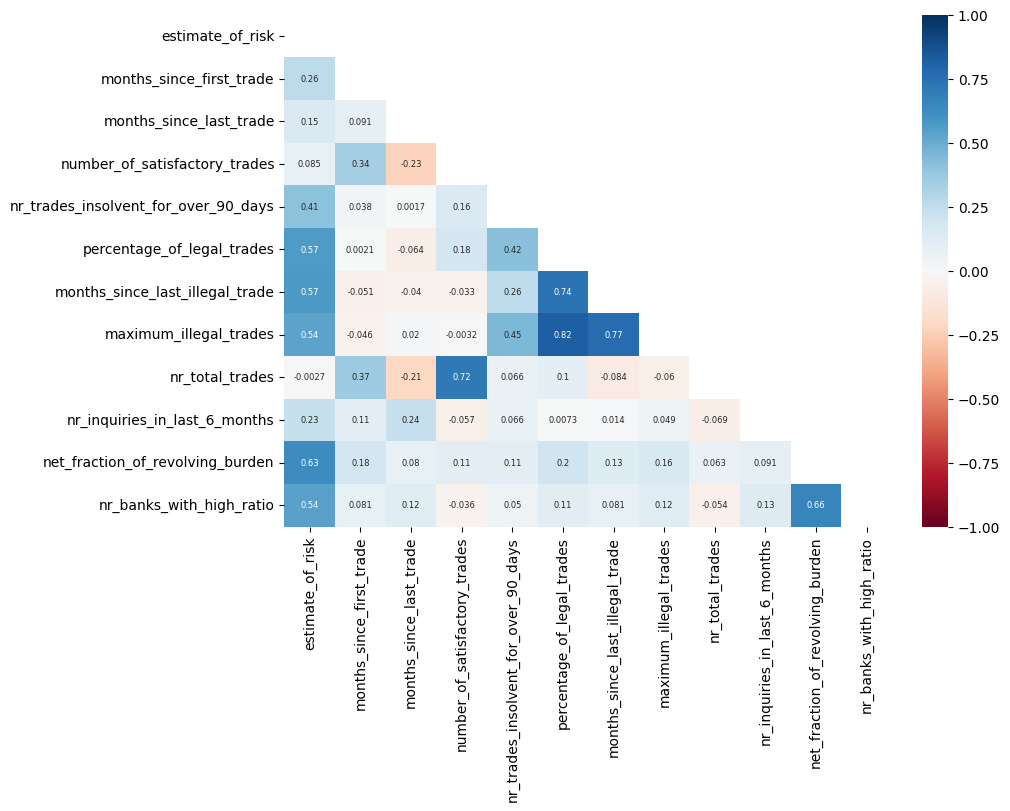

In [50]:
X_train_corr = X_train_woe[preselected_features].corr()
plot_correlations(X_train_corr)

In [51]:
corr_limit = 0.6  # correlation threshold

drop_feats = list()

# keep_feats = list()

for ix, feature in enumerate(preselected_features):
    if feature in drop_feats:
        continue

    remaining_features = [
        feat
        for feat in preselected_features[ix:]  # check the next feature in the preselected step
        if feat not in drop_feats and feat != feature
    ]
    if len(remaining_features) == 0:
        continue  # go to the next step if the features at step x have already been removeed

    # find the correlated features with the remaining preselected features
    # both positive and negative correlations matter, hence the abs()
    corr_feats = X_train_corr.loc[remaining_features, feature].apply(lambda x: abs(x))

    drop_at_step = corr_feats[corr_feats > corr_limit].index.tolist()

    # append the new features to the list
    drop_feats += drop_at_step

# Select the features with low correlations
good_feats = [feat for feat in preselected_features if feat not in drop_feats]

print(f"Total preselected features: {len(preselected_features)}")
print(f"Total features dropped due too high correlations: {len(drop_feats)}")
print(f"Total selected features: {len(good_feats)}")

Total preselected features: 12
Total features dropped due too high correlations: 4
Total selected features: 8


In [52]:
drop_feats

['net_fraction_of_revolving_burden',
 'nr_total_trades',
 'months_since_last_illegal_trade',
 'maximum_illegal_trades']

In [53]:
good_feats

['estimate_of_risk',
 'months_since_first_trade',
 'months_since_last_trade',
 'number_of_satisfactory_trades',
 'nr_trades_insolvent_for_over_90_days',
 'percentage_of_legal_trades',
 'nr_inquiries_in_last_6_months',
 'nr_banks_with_high_ratio']

# Retraining the Model Using the Best Features

In [54]:
df = df_original.copy()

# Same remap as earlier: OpenML's column -> name used downstream
if 'NumTrades90Ever2DerogPubRec' in df.columns and 'nr_trades_insolvent_for_over_90_days' not in df.columns:
    df = df.rename(columns={'NumTrades90Ever2DerogPubRec': 'nr_trades_insolvent_for_over_90_days'})

features = ['estimate_of_risk', 'months_since_first_trade', 'months_since_last_trade', 'number_of_satisfactory_trades',
            'nr_trades_insolvent_for_over_90_days', 'percentage_of_legal_trades',
            'nr_inquiries_in_last_6_months', 'nr_banks_with_high_ratio']
X = df[features]
y = df['is_at_risk'].astype(int)  # category -> int, as before

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [55]:
import warnings
warnings.filterwarnings("ignore")

# Special values definition
specials = {
    "estimate_of_risk": {'=NA, No Usable Data, Not Investigated': [-7, -8, -9]},
    "months_since_first_trade":{'=NA, No Usable Data, Not Investigated': [-7, -8, -9]},
    "months_since_last_trade": {'=NA, No Usable Data, Not Investigated': [-7, -8, -9]},
    "number_of_satisfactory_trades": {'=NA, No Usable Data, Not Investigated': [-7, -8, -9]},
    "nr_trades_insolvent_for_over_90_days": {'=NA, No Usable Data, Not Investigated': [-7, -8, -9]},
    "percentage_of_legal_trades": {'=NA, No Usable Data, Not Investigated': [-7, -8, -9]},
    "nr_inquiries_in_last_6_months": {'=NA, No Usable Data, Not Investigated': [-7, -8, -9]},
    "nr_banks_with_high_ratio": {'=NA, No Usable Data, Not Investigated': [-7, -8, -9]},
}

num_cols = ['estimate_of_risk', 'months_since_first_trade', 'months_since_last_trade', 'number_of_satisfactory_trades',
            'nr_trades_insolvent_for_over_90_days', 'percentage_of_legal_trades',
            'nr_inquiries_in_last_6_months', 'nr_banks_with_high_ratio']

# Create and fit bucketing process on training data
bucketing_process = BucketingProcess(
    prebucketing_pipeline=make_pipeline(
        EqualWidthBucketer(n_bins=100, variables=num_cols)
    ),
    bucketing_pipeline=make_pipeline(
        DecisionTreeBucketer(variables=num_cols, max_n_bins=10, min_bin_size=0.05, random_state=42)
    ),
    specials=specials
)
bucketing_process.fit(X_train, y_train)

BucketingProcess(bucketing_pipeline=Pipeline(steps=[('decisiontreebucketer',
                                                     DecisionTreeBucketer(max_n_bins=10,
                                                                          random_state=42,
                                                                          variables=['estimate_of_risk',
                                                                                     'months_since_first_trade',
                                                                                     'months_since_last_trade',
                                                                                     'number_of_satisfactory_trades',
                                                                                     'nr_trades_insolvent_for_over_90_days',
                                                                                     'percentage_of_legal_trades',
                                                                                     'nr_inquiries_in_last_6_months',
                                                                                     'nr_bank...
                           'nr_banks_with_high_ratio': {'=NA, No Usable Data, Not Investigated': [-7,
                                                                                                  -8,
                                                                                                  -9]},
                           'nr_inquiries_in_last_6_months': {'=NA, No Usable Data, Not Investigated': [-7,
                                                                                                       -8,
                                                                                                       -9]},
                           'nr_trades_insolvent_for_over_90_days': {'=NA, No Usable Data, Not Investigated': [-7,
                                                                                                              -8,
                                                                                                              -9]},
                           'number_of_satisfactory_trades': {'=NA, No Usable Data, Not Investigated': [-7,
                                                                                                       -8,
                                                                                                       -9]},
                           'percentage_of_legal_trades': {'=NA, No Usable Data, Not Investigated': [-7,
                                                                                                    -8,
                                                                                                    -9]}})

In [56]:
from skorecard.pipeline import to_skorecard_pipeline
bucketing_process.save_yml(open("buckets.yml", "w"))

In [57]:
import yaml

buckets_dict = yaml.safe_load(open("buckets.yml"))

In [58]:
from skorecard import Skorecard
from skorecard.bucketers import UserInputBucketer

scorecard = Skorecard(bucketing=UserInputBucketer(buckets_dict), variables=num_cols, calculate_stats=True)
scorecard = scorecard.fit(X_train, y_train)

In [59]:
scorecard.get_stats()

,Coef.,Std.Err,z,P>|z|
const,0.090528,0.025227,3.588565,3.325034e-04
estimate_of_risk,0.722959,0.041091,17.594133,2.732030e-69
months_since_first_trade,0.502920,0.060794,8.272600,1.310690e-16
months_since_last_trade,0.356815,0.191563,1.862649,6.251173e-02
number_of_satisfactory_trades,0.849882,0.086933,9.776340,1.422622e-22
nr_trades_insolvent_for_over_90_days,-0.096853,0.077014,-1.257609,2.085330e-01
percentage_of_legal_trades,0.325738,0.056259,5.790012,7.038143e-09
nr_inquiries_in_last_6_months,0.507576,0.084908,5.977965,2.259424e-09
nr_banks_with_high_ratio,0.347390,0.052925,6.563790,5.245715e-11


In [60]:
from sklearn.metrics import roc_auc_score, classification_report

proba_train = scorecard.predict_proba(X_train)[:, 1]
proba_test = scorecard.predict_proba(X_test)[:, 1]

print(f"AUC train:{round(roc_auc_score(y_train, proba_train),4)}")
print(f"AUC test :{round(roc_auc_score(y_test, proba_test),4)}\n")

print(classification_report(y_test, scorecard.predict(X_test)))

AUC train:0.7844
AUC test :0.784

              precision    recall  f1-score   support

           0       0.73      0.67      0.70      1023
           1       0.71      0.76      0.73      1069

    accuracy                           0.72      2092
   macro avg       0.72      0.72      0.72      2092
weighted avg       0.72      0.72      0.72      2092



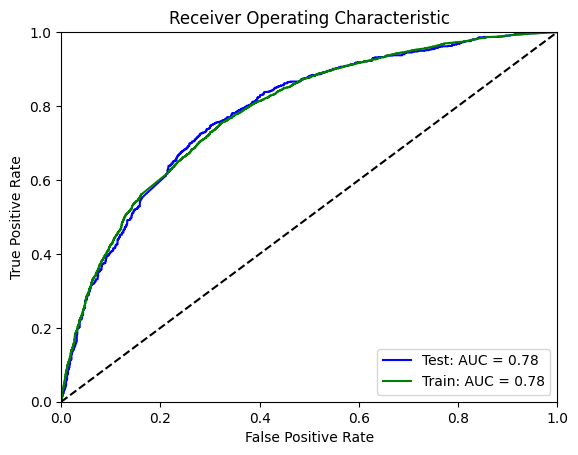

In [61]:
from matplotlib import pyplot as plt
from sklearn.metrics import roc_curve, auc

fpr1, tpr1, threshold1 = roc_curve(y_test, proba_test)
roc_auc1 = auc(fpr1, tpr1)

fpr2, tpr2, threshold2 = roc_curve(y_train, proba_train)
roc_auc2 = auc(fpr2, tpr2)

plt.title('Receiver Operating Characteristic')
plt.plot(fpr1, tpr1, 'b', label='Test: AUC = {0:.2f}'.format(roc_auc1))
plt.plot(fpr2, tpr2, 'g', label='Train: AUC = {0:.2f}'.format(roc_auc2))
plt.legend(loc='lower right')
plt.plot([0, 1], [0, 1],'k--')
plt.xlim([0, 1])
plt.ylim([0, 1])
plt.ylabel('True Positive Rate')
plt.xlabel('False Positive Rate')
plt.show()

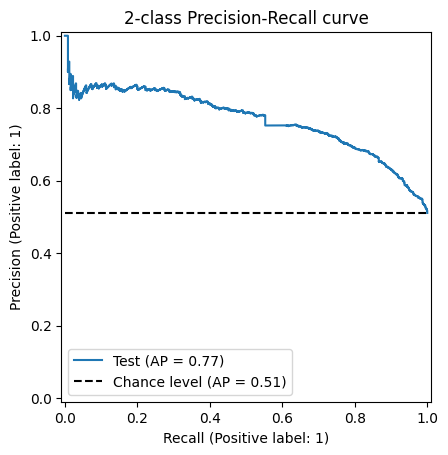

In [62]:
from sklearn.metrics import PrecisionRecallDisplay

display = PrecisionRecallDisplay.from_estimator(
    scorecard, X_test, y_test, name="Test", plot_chance_level=True
)
_ = display.ax_.set_title("2-class Precision-Recall curve")

# Challenger Model
XGBoost
- Boosted Trees can capture complex patterns and interactions between features and effectively model non-linear relationships between variables. Boosted Trees can provide high predictive accuracy and are robust to overfitting, especially when properly tuned.

In [63]:
df = df_original.copy()

# Same remap as earlier: OpenML's column -> name used downstream
if 'NumTrades90Ever2DerogPubRec' in df.columns and 'nr_trades_insolvent_for_over_90_days' not in df.columns:
    df = df.rename(columns={'NumTrades90Ever2DerogPubRec': 'nr_trades_insolvent_for_over_90_days'})

features = ['estimate_of_risk', 'months_since_first_trade', 'months_since_last_trade', 'number_of_satisfactory_trades',
            'nr_trades_insolvent_for_over_90_days', 'percentage_of_legal_trades',
            'nr_inquiries_in_last_6_months', 'nr_banks_with_high_ratio']
X = df[features]
y = df['is_at_risk'].astype(int)  # category -> int, as before

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [64]:
import xgboost as xgb

xgb_mod = xgb.XGBClassifier(objective='reg:logistic', colsample_bytree=0.2, alpha=10,
                            learning_rate=0.1, max_depth=4, n_estimators=100)
xgb_mod.fit(X_train,y_train)

XGBClassifier(alpha=10, base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.2, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=4,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=100,
              n_jobs=None, ...)

In [65]:
from sklearn.metrics import f1_score
from sklearn.metrics import accuracy_score

xgb_pred = xgb_mod.predict(X_test)
print('Training accuracy:', accuracy_score(y_train, xgb_mod.predict(X_train)))
print('Test accuracy:', accuracy_score(y_test, xgb_pred))

Training accuracy: 0.71686386996534
Test accuracy: 0.719885277246654


In [66]:
proba_train_xgb = xgb_mod.predict_proba(X_train)[:, 1]
proba_test_xgb = xgb_mod.predict_proba(X_test)[:, 1]

print(f"AUC train:{round(roc_auc_score(y_train, proba_train_xgb),4)}")
print(f"AUC test :{round(roc_auc_score(y_test, proba_test_xgb),4)}\n")

print(classification_report(y_test, xgb_mod.predict(X_test)))

AUC train:0.7858
AUC test :0.7807

              precision    recall  f1-score   support

           0       0.74      0.67      0.70      1023
           1       0.71      0.77      0.74      1069

    accuracy                           0.72      2092
   macro avg       0.72      0.72      0.72      2092
weighted avg       0.72      0.72      0.72      2092



- The XGBoost challenger performs essentially the same as the retrained scorecard: test accuracy is 0.72 for both, and per-class precision, recall and F1 differ by at most 0.01.
- The scorecard has a slightly higher test AUC (0.784 vs. 0.781).
- Since the more complex model adds no predictive lift, the retrained scorecard was chosen for deployment. It is easier to interpret and explain, which matters for credit decisions.

# Deployment

### Post Processing: Convert to Scores


Convert the probabilities to scores. [Credit scorecard development process](https://medium.com/@yanhuiliu104/credit-scoring-scorecard-development-process-8554c3492b2b)

In [67]:
from skorecard.rescale import calibrate_to_master_scale
import numpy as np

proba_train = pd.Series(proba_train, index=X_train.index).sort_values()

ref_score = 400
ref_odds = 3
pdo = 20

scores = calibrate_to_master_scale(proba_train, pdo=pdo, ref_score=ref_score, ref_odds=ref_odds)

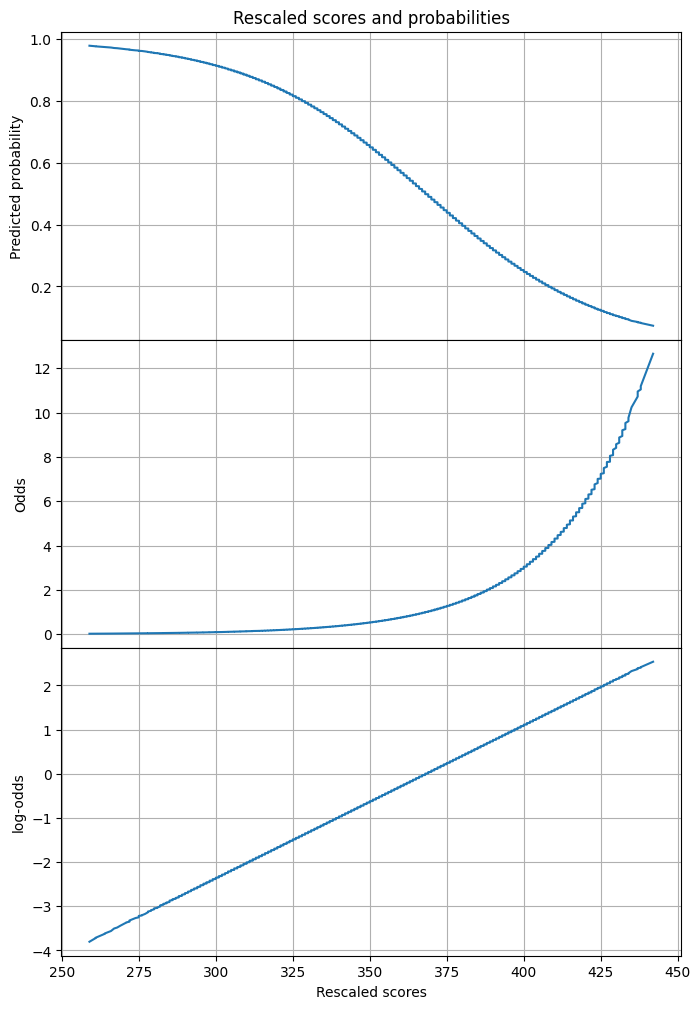

In [68]:
import matplotlib.pyplot as plt

fig, (ax1, ax2, ax3) = plt.subplots(3, sharex=True, figsize=(8, 12), gridspec_kw={"hspace": 0})
ax1.plot(scores.values, proba_train.values)

ax1.set_ylabel("Predicted probability")
ax1.set_title("Rescaled scores and probabilities")
ax1.grid()


ax2.plot(scores.values, proba_train.apply(lambda x: (1 - x) / x).values)
ax2.set_ylabel("Odds")
ax2.grid()


ax3.plot(
    scores.values,
    proba_train.apply(lambda x: np.log(1 - x) - np.log(x)).values,
)
ax3.set_ylabel("log-odds")
ax3.grid()
ax3.set_xlabel("Rescaled scores")

plt.show()

In [69]:
from skorecard.rescale import ScoreCardPoints

# ensure that pdo, ref_score and ref_odds are consistent
scp = ScoreCardPoints(skorecard_model=scorecard, pdo=20, ref_score=400, ref_odds=3)

In [70]:
scp.get_scorecard_points()

,bin_index,map,woe,feature,coef,contribution,Points
0,0,"(-inf, 59.230000000000004]",0.014111,estimate_of_risk,0.722959,0.010201,45
1,1,"(59.230000000000004, 63.5]",-1.221049,estimate_of_risk,0.722959,-0.882768,71
2,2,"(63.5, 67.16]",1.700910,estimate_of_risk,0.722959,1.229688,10
3,3,"(67.16, 70.21000000000001]",1.183061,estimate_of_risk,0.722959,0.855304,21
4,4,"(70.21000000000001, 73.25999999999999]",-1.737180,estimate_of_risk,0.722959,-1.255909,82
5,5,"(73.25999999999999, 76.31]",-0.331948,estimate_of_risk,0.722959,-0.239985,53
6,6,"(76.31, 81.19]",0.394988,estimate_of_risk,0.722959,0.285560,37
7,7,"(81.19, 84.24000000000001]",0.800729,estimate_of_risk,0.722959,0.578894,29
8,8,"(84.24000000000001, inf]",0.103161,estimate_of_risk,0.722959,0.074581,44
9,-1,Missing,0.000000,estimate_of_risk,0.722959,0.000000,46


In [71]:
df_score = scp.transform(X_test)
df_score['score'] = df_score.sum(axis=1, skipna=True)
df_score.head(10)

,estimate_of_risk,months_since_first_trade,months_since_last_trade,number_of_satisfactory_trades,nr_trades_insolvent_for_over_90_days,percentage_of_legal_trades,nr_inquiries_in_last_6_months,nr_banks_with_high_ratio,score
7528,82.0,51.0,45.0,34.0,45.0,43.0,44.0,52.0,396.0
7406,53.0,39.0,45.0,55.0,45.0,43.0,50.0,NaN,330.0
2473,82.0,51.0,45.0,47.0,45.0,34.0,36.0,52.0,392.0
1418,45.0,49.0,50.0,34.0,45.0,34.0,50.0,44.0,351.0
2150,37.0,45.0,45.0,47.0,45.0,43.0,46.0,40.0,348.0
7719,29.0,45.0,46.0,51.0,45.0,43.0,42.0,40.0,341.0
761,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
1950,53.0,28.0,45.0,47.0,45.0,43.0,36.0,52.0,349.0
10214,82.0,48.0,46.0,47.0,45.0,45.0,42.0,52.0,407.0
9292,21.0,48.0,46.0,42.0,45.0,45.0,46.0,40.0,333.0


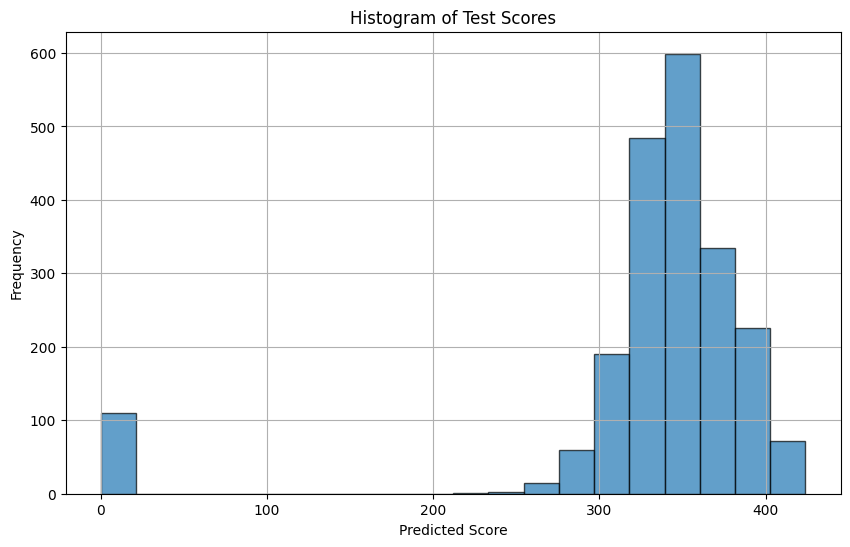

In [72]:
import matplotlib.pyplot as plt

# Create a histogram of the 'Score' column
plt.figure(figsize=(10, 6))
plt.hist(df_score['score'], bins=20, edgecolor='k', alpha=0.7)
plt.title('Histogram of Test Scores')
plt.xlabel('Predicted Score')
plt.ylabel('Frequency')
plt.grid(True)
plt.show()

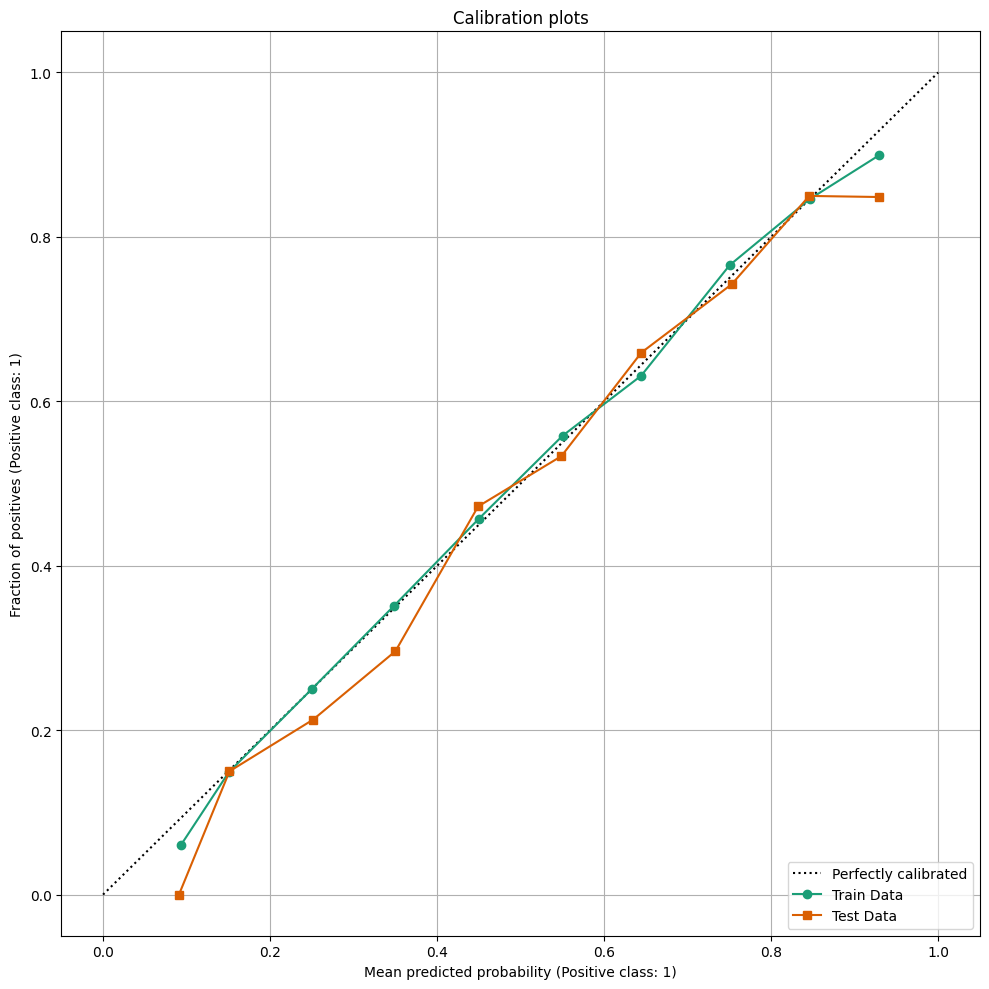

In [73]:
from matplotlib.gridspec import GridSpec
from sklearn.calibration import CalibrationDisplay

proba_train = scorecard.predict_proba(X_train)[:, 1]
proba_test = scorecard.predict_proba(X_test)[:, 1]

fig = plt.figure(figsize=(10, 10))
gs = GridSpec(2, 2)
colors = plt.get_cmap("Dark2")

ax_calibration_curve = fig.add_subplot(gs[:, :])


calibration_display_train = CalibrationDisplay.from_predictions(
    y_train,
    proba_train,
    n_bins=10,
    name="Train Data",
    ax=ax_calibration_curve,
    color=colors(0),
    marker='o'
)

# Display calibration curve for test data
calibration_display_test = CalibrationDisplay.from_predictions(
    y_test,
    proba_test,
    n_bins=10,
    name="Test Data",
    ax=ax_calibration_curve,
    color=colors(1),
    marker='s'
)

ax_calibration_curve.grid()
ax_calibration_curve.set_title("Calibration plots")

plt.tight_layout()
plt.show()

## Interpretation

- According to the calibration plots, the model is relatively close to the perfect calibration line suggesting that both the training and test data are well-calibrated and the predicted probabilities from the model are close to the actual probabilities of the outcomes.

- There is a small gap between the train and test data which indicates that there is a minor difference between the calibration of the model on the training data and the test data meaning the model's performance on the training set is slightly different from its performance on the test set.

--------------------------------------------------------------------------------

##  Population Stability Index (PSI)
Measures how much a population's characteristics have changed over time by comparing the distribution of variables in an original training dataset to a newer dataset. It helps determine if the predictive model is still relevant or if it needs updating.

A low PSI score indicates stability, while a high score suggests significant population change that may require model recalibration or retraining.

| PSI | Interpretation     |
|:-----------------:|-----------------------------|
| PSI < 0.1 | No change. You can continue using existing model. |
| 0.1 <= PSI >= < 0.2 | Slight change is required. |
| PSI >=0.2 | Significant change is required. Ideally, you should not use this model anymore, retraining is required. |


In [74]:
from skorecard.bucketers import EqualWidthBucketer
from skorecard.reporting import psi

bucketer = EqualWidthBucketer()
bucketer.fit(X_train)

X_train_bins = bucketer.fit_transform(X_train)
X_test_bins = bucketer.transform(X_test)

psi_values = psi(X_train_bins, X_test_bins)
psi_values

{'estimate_of_risk': np.float64(0.0005036570228626072),
 'months_since_first_trade': np.float64(0.005133906232564),
 'months_since_last_trade': np.float64(0.0008652597185708924),
 'number_of_satisfactory_trades': np.float64(0.0034418235683056366),
 'nr_trades_insolvent_for_over_90_days': np.float64(0.0012926532168005852),
 'percentage_of_legal_trades': np.float64(0.0016500985392673068),
 'nr_inquiries_in_last_6_months': np.float64(0.0007852052366107947),
 'nr_banks_with_high_ratio': np.float64(0.0034915206882044298)}

# Interpretation

Based on these PSI values, all variables show excellent stability, indicating the model's performance is likely very consistent over time.

All PSI scores are well below 0.1, suggesting minimal shifts in the population characteristics.

This implies that the model should maintain its predictive accuracy and reliability without immediate need for recalibration or retraining.



In [75]:
# define fpr_score, assign pos_label/neg_label, and create scoring
from sklearn.metrics import confusion_matrix
from sklearn.metrics import make_scorer, precision_score, recall_score

pos_label, neg_label = "bad", "good"

def fpr_score(y, y_pred, neg_label, pos_label):
    cm = confusion_matrix(y, y_pred, labels=[neg_label, pos_label])
    tn, fp, _, _ = cm.ravel()
    tnr = tn / (tn + fp)
    return 1 - tnr

tpr_score = recall_score  # TPR and recall are the same metric
scoring = {
    "precision": make_scorer(precision_score, pos_label=1),
    "recall": make_scorer(recall_score, pos_label=1),
    "fpr": make_scorer(fpr_score, neg_label=0, pos_label=1),
    "tpr": make_scorer(tpr_score, pos_label=1),
}

In [76]:
# define credit_gain_score (correctly updating gain_matrix) and run it

import numpy as np

def credit_gain_score(y, y_pred, neg_label, pos_label):
    cm = confusion_matrix(y, y_pred, labels=[neg_label, pos_label])
    # The rows of the confusion matrix hold the counts of observed classes
    # while the columns hold counts of predicted classes. Recall that here we
    # consider "bad" as the positive class (second row and column).
    # Scikit-learn model selection tools expect that we follow a convention
    # that "higher" means "better", hence the following gain matrix assigns
    # negative gains (costs) to the two kinds of prediction errors:
    # - a gain of -1 for each false positive ("good" credit labeled as "bad"),
    # - a gain of -5 for each false negative ("bad" credit labeled as "good"),
    # The true positives and true negatives are assigned null gains in this
    # metric.
    #
    # Note that theoretically, given that our model is calibrated and our data
    # set representative and large enough, we do not need to tune the
    # threshold, but can safely set it to the cost ration 1/5, as stated by Eq.
    # (2) in Elkan paper [2]_.
    gain_matrix = np.array(
        [
            [0, -1],  # -1 gain for false positives
            [-5, 0],  # -5 gain for false negatives
        ]
    )
    return np.sum(cm * gain_matrix)


scoring["cost_gain"] = make_scorer(
    credit_gain_score, neg_label=0, pos_label=1
)

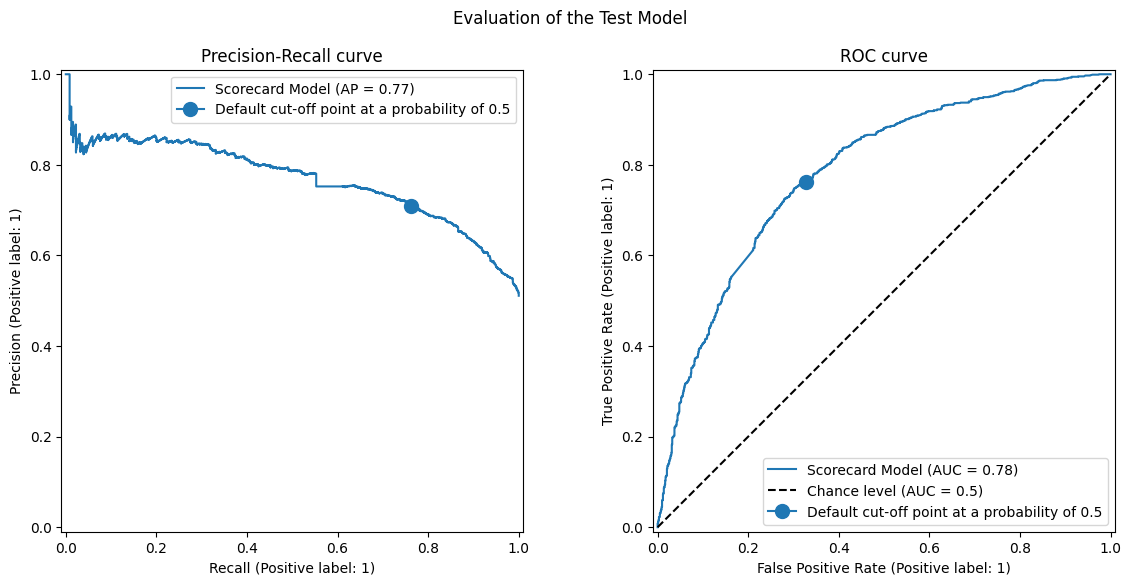

In [77]:
# plot Precision-Recall at 50% using PrecisionRecallDisplay and RocCurveDisplay
import matplotlib.pyplot as plt
from sklearn.metrics import PrecisionRecallDisplay, RocCurveDisplay

model = scorecard

fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(14, 6))

PrecisionRecallDisplay.from_estimator(
    model, X_test, y_test, pos_label=1, ax=axs[0], name="Scorecard Model"
)
axs[0].plot(
    scoring["recall"](model, X_test, y_test),
    scoring["precision"](model, X_test, y_test),
    marker="o",
    markersize=10,
    color="tab:blue",
    label="Default cut-off point at a probability of 0.5",
)
axs[0].set_title("Precision-Recall curve")
axs[0].legend()

RocCurveDisplay.from_estimator(
    model,
    X_test,
    y_test,
    pos_label=1,
    ax=axs[1],
    name="Scorecard Model",
    plot_chance_level=True,
)
axs[1].plot(
    scoring["fpr"](model, X_test, y_test),
    scoring["tpr"](model, X_test, y_test),
    marker="o",
    markersize=10,
    color="tab:blue",
    label="Default cut-off point at a probability of 0.5",
)
axs[1].set_title("ROC curve")
axs[1].legend()
_ = fig.suptitle("Evaluation of the Test Model")

In [78]:
# Using TunedThresholdClassifierCV to tune threshold
from sklearn.model_selection import TunedThresholdClassifierCV

tuned_model = TunedThresholdClassifierCV(
    estimator=model,
    scoring=scoring["cost_gain"],
    store_cv_results=True,  # necessary to inspect all results
)
tuned_model.fit(X_train, y_train)
print(f"{tuned_model.best_threshold_=:0.2f}")

tuned_model.best_threshold_=0.15


# Performance at the tuned threshold (0.15) on the test set

In [79]:
print(classification_report(y_test, tuned_model.predict(X_test)))

              precision    recall  f1-score   support

           0       0.91      0.10      0.18      1023
           1       0.53      0.99      0.69      1069

    accuracy                           0.55      2092
   macro avg       0.72      0.54      0.44      2092
weighted avg       0.72      0.55      0.44      2092



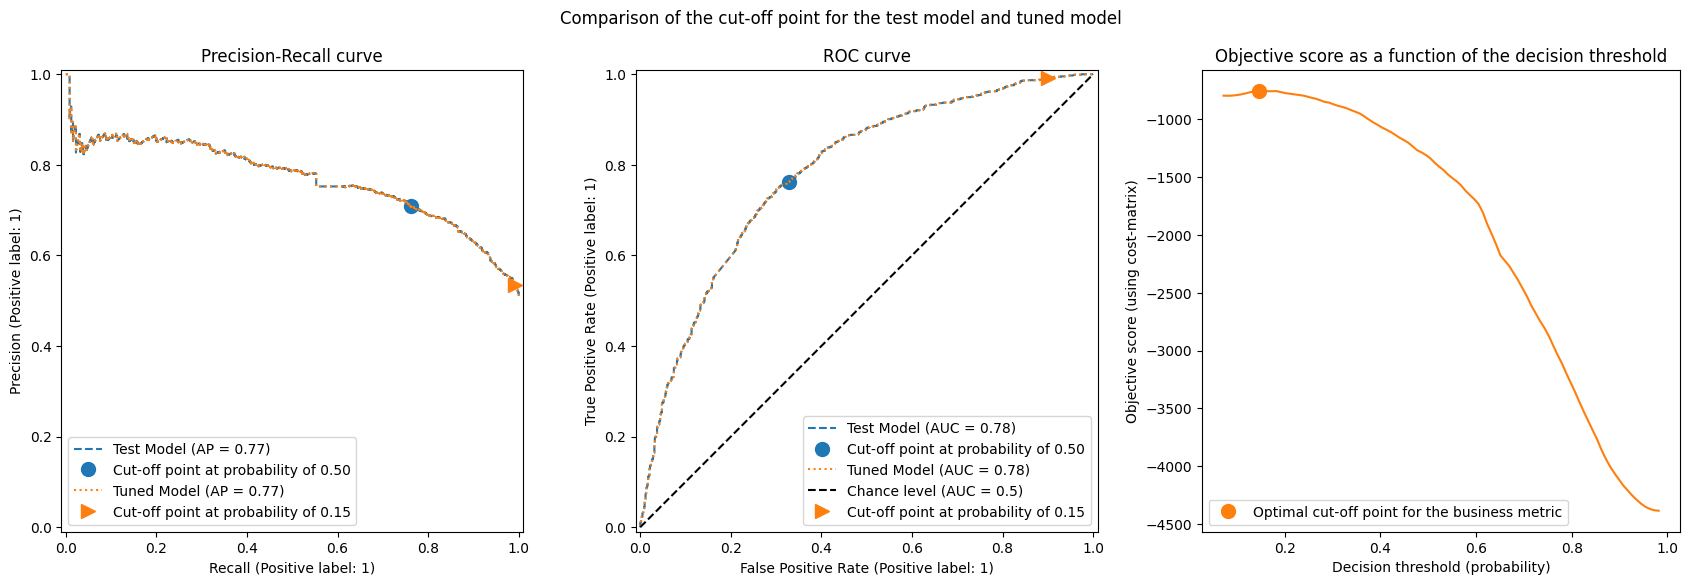

In [80]:
# define and run plot_roc_pr_curves
def plot_roc_pr_curves(model, tuned_model, *, title):
    fig, axs = plt.subplots(nrows=1, ncols=3, figsize=(21, 6))

    linestyles = ("dashed", "dotted")
    markerstyles = ("o", ">")
    colors = ("tab:blue", "tab:orange")
    names = ("Test Model", "Tuned Model")
    for idx, (est, linestyle, marker, color, name) in enumerate(
        zip((model, tuned_model), linestyles, markerstyles, colors, names)
    ):
        decision_threshold = getattr(est, "best_threshold_", 0.5)
        PrecisionRecallDisplay.from_estimator(
            est,
            X_test,
            y_test,
            pos_label=1,
            linestyle=linestyle,
            color=color,
            ax=axs[0],
            name=name,
        )
        axs[0].plot(
            scoring["recall"](est, X_test, y_test),
            scoring["precision"](est, X_test, y_test),
            marker,
            markersize=10,
            color=color,
            label=f"Cut-off point at probability of {decision_threshold:.2f}",
        )
        RocCurveDisplay.from_estimator(
            est,
            X_test,
            y_test,
            pos_label=1,
            linestyle=linestyle,
            color=color,
            ax=axs[1],
            name=name,
            plot_chance_level=idx == 1,
        )
        axs[1].plot(
            scoring["fpr"](est, X_test, y_test),
            scoring["tpr"](est, X_test, y_test),
            marker,
            markersize=10,
            color=color,
            label=f"Cut-off point at probability of {decision_threshold:.2f}",
        )

    axs[0].set_title("Precision-Recall curve")
    axs[0].legend()
    axs[1].set_title("ROC curve")
    axs[1].legend()

    axs[2].plot(
        tuned_model.cv_results_["thresholds"],
        tuned_model.cv_results_["scores"],
        color="tab:orange",
    )
    axs[2].plot(
        tuned_model.best_threshold_,
        tuned_model.best_score_,
        "o",
        markersize=10,
        color="tab:orange",
        label="Optimal cut-off point for the business metric",
    )
    axs[2].legend()
    axs[2].set_xlabel("Decision threshold (probability)")
    axs[2].set_ylabel("Objective score (using cost-matrix)")
    axs[2].set_title("Objective score as a function of the decision threshold")
    fig.suptitle(title)

title = "Comparison of the cut-off point for the test model and tuned model"
plot_roc_pr_curves(model, tuned_model, title=title)

# Discussion and Business Insights:

- **Discrimination:** The retrained scorecard achieves an Average Precision (AP) of 0.77 and a ROC AUC of 0.78 on the test set.

- **Threshold tuning:** Tuning the decision threshold does not change AP or AUC. Those metrics measure how well the model ranks applicants, and the threshold only moves the cut-off point along the same curve. The identical values for the test and tuned models are therefore expected. What tuning changes is the trade-off between catching risky applicants and flagging safe ones.

- **Business trade-off:** Using the cost matrix (a missed at-risk applicant costs 5x as much as a wrongly flagged safe one), the optimal cut-off is a probability of 0.15, compared with the default of 0.50:

  | Threshold | At-risk recall | At-risk precision | Safe applicants approved (class 0 recall) | Accuracy |
  |:---:|:---:|:---:|:---:|:---:|
  | 0.50 | 0.76 | 0.71 | 0.67 | 0.72 |
  | 0.15 | 0.99 | 0.53 | 0.10 | 0.55 |

  At the tuned threshold, the model catches 99% of at-risk applicants but flags 90% of safe applicants as well. In practice, this works as a screening step that sends most applications to manual review rather than as an approval model. Whether that is acceptable depends on the real cost of a review compared with a default; the 5:1 cost ratio is an assumption, and a less extreme ratio would produce a more balanced threshold.

- **Consistency with theory:** The tuned threshold (0.15) is close to the theoretical cut-off of 1/(1+5) ≈ 0.17 implied by the cost ratio, which supports the calibration-plot finding that the predicted probabilities are reliable.

- **Generalization:** Train and test AUC are nearly identical, and all PSI values are well below 0.1. The small differences between train and test event rates observed earlier do not meaningfully affect overall performance.

# Conclusion:
- The retrained scorecard for predicting HELOC repayment risk performs consistently on unseen data (test AUC 0.78, AP 0.77) and is well calibrated, so its predicted probabilities can be used directly for decision-making.
- An XGBoost challenger offered no meaningful improvement, so the more interpretable scorecard was selected.
- The choice of decision threshold drives the business outcome. The default 0.50 cut-off balances the two classes (accuracy 0.72), while the cost-based 0.15 cut-off catches 99% of at-risk applicants but approves only 10% of safe ones. The final threshold should be set from the lender's actual costs for defaults and manual reviews.

# Unexpected findings or challenges:
- The more flexible XGBoost model did not outperform the logistic-regression scorecard. This suggests the relationships in this dataset are largely captured by the binned, linear scorecard, or that the available features limit predictive power more than the choice of algorithm does.
- Applying the 5:1 cost matrix pushed the optimal threshold down to 0.15, which flags 90% of safe applicants. This shows how sensitive the model's business value is to the assumed cost ratio.
- The model relies heavily on estimate_of_risk (IV 0.97). If this external estimate changed or became unavailable, performance could drop significantly.
- Several package incompatibilities (skorecard with newer versions of scikit-learn, category_encoders and NumPy) required pinning older versions and patching the code, which is a maintenance risk for deploying this library.

# Future Work:

- Feature Engineering: create new features by combining existing ones or deriving new metrics. This can help uncover hidden patterns and improve model performance.

Examples:
  - Trade activity ratio: Divide 'number_of_satisfactory_trades' by 'months_since_first_trade'. This could indicate the frequency of positive trade activity over time.
  - Risk-adjusted trade score: Multiply 'estimate_of_risk' by (1 - 'percentage_of_legal_trades'). This combines risk estimate with legal compliance.
  - Recent activity indicator: Create a binary feature that's 1 if 'months_since_last_trade' is less than a certain threshold (3 months), 0 otherwise. This could highlight recently active accounts.

- Model Experimentation: Trying different ML algorithms like PCA and SVM and implementing ensemble methods to combine multiple models which can often lead to better overall performance than relying on a single algorithm.

- Hyperparameter Tuning: Instead of Cross Validation, using Bayesian Optimization with cross-validation to fine-tune the model parameters.